# 📈 PREP_01 — Feature Engineering Indikator Teknikal (REVISI v2)
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45

| | |
|---|---|
| **Mahasiswa** | Ilda Nurida (NRP 6032251068) |
| **Program Studi** | Magister Manajemen Teknologi — SIMT ITS |
| **Pembimbing** | Dr. Ir. Ahmad Saikhu, S.Si, MT. |
| **Tahun** | 2026 |

---

### 🎯 Perubahan Utama vs Versi Sebelumnya (Audit + Diskusi Redesain Fitur)

1. **Y direstrukturisasi jadi target FORECAST (h+1), bukan NOWCAST.**
   Sebelumnya `Volatilitas(t)` dihitung dari `Log_Return[t-19..t]` lalu langsung
   dipakai sebagai Y pada baris waktu `t` yang sama dengan fitur X(t) — termasuk
   `Log_Return(t)` itu sendiri ikut jadi salah satu komponen std dalam Y(t).
   Ini kemungkinan besar penyebab **R² negatif**: model diminta 'memprediksi'
   sesuatu yang sebagian dibentuk dari input hari yang sama. Sekarang:
   $$Y_t = \text{Volatilitas}_{t+1} \quad (\text{target di-}\textit{shift}(-1))$$
   sehingga fitur di hari $t$ benar-benar dipakai memprediksi kondisi $t+1$.

2. **Fitur level harga (MA5/MA10/MA20 mentah) diganti rasio stasioner**
   `MA5_Ratio = Close/MA5 - 1`, dst. MA mentah sangat kolinear dengan `Close`
   dan tidak stasioner — buruk untuk LSTM.

3. **`Volume_ZScore` dikembalikan sebagai satu-satunya fitur volume**
   (bukan raw `Volume`, yang scale-dependent antar emiten).

4. **MACD & Bollinger Bands dihapus** (redundan/kolinear dengan MA & harga,
   tidak relevan langsung untuk target varians — lihat diskusi metodologi).

5. **`Open` ditambahkan kembali** ke kolom OHLCV (sempat hilang di versi lama).

### 📊 Fitur Final

**Kolom referensi (bukan input model, untuk EDA/plot Bab 4):**
`Open, High, Low, Close, Volume, MA5, MA10, MA20`

**X1 — Fitur Teknikal (13 kolom, INPUT MODEL):**
`Log_Return, Vol_Lag1, Vol_Lag2, Vol_Lag3, Vol_MA5, Vol_STD5, MA5_Ratio, MA10_Ratio, MA20_Ratio, RSI14, Stoch_K, Stoch_D, Volume_ZScore`

**Y — Target (1 kolom):** `Volatilitas_Target` (= volatilitas $t+1$, hasil `shift(-1)`)

**X2 — Sentimen (belum di notebook ini, disiapkan di notebook IndoBERT terpisah):** `Sentiment_Mean(t-1), Sentiment_Dispersion(t-1), News_Count(t-1)` — pakai lag $t-1$ karena berita hari $t$ seringkali bereaksi terhadap harga hari $t$ (reverse causality), bukan menyebabkannya.

---
## CELL 1 — Import Library dan Konfigurasi Path

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import os
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family' : 'Times New Roman',
    'font.size'   : 10,
    'figure.dpi'  : 150,
})

# ═══════════════════════════════════════════════════════════
# PATH — DETEKSI OTOMATIS
# ═══════════════════════════════════════════════════════════
from pathlib import Path

NOTEBOOK_DIR = Path(os.getcwd())
ROOT = NOTEBOOK_DIR
for _ in range(5):
    if (ROOT / '03_dataset').exists():
        break
    ROOT = ROOT.parent

# ── Path Input
PATH_VOLATILITAS = ROOT / '03_dataset' / 'processed' / 'volatilitas.csv'
PATH_HARGA_RAW   = ROOT / '03_dataset' / 'raw'       / 'harga_saham_raw.csv'

# ── Path Output
DIR_PROCESSED    = ROOT / '03_dataset'     / 'processed'
DIR_TABEL        = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR       = ROOT / '06_dokumen_tesis' / 'gambar' / 'EDA'

for d in [DIR_PROCESSED, DIR_TABEL, DIR_GAMBAR]:
    d.mkdir(parents=True, exist_ok=True)

# ── Konfigurasi penelitian
URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']

NAMA_PERUSAHAAN = {
    'ADRO': 'Adaro Energy Indonesia Tbk',
    'ADMR': 'Adaro Minerals Indonesia Tbk',
    'ITMG': 'Indo Tambangraya Megah Tbk',
    'PTBA': 'Bukit Asam Tbk',
    'MEDC': 'Medco Energi Internasional Tbk',
    'AKRA': 'AKR Corporindo Tbk',
    'PGAS': 'Perusahaan Gas Negara Tbk',
}

WARNA_EMITEN = {
    'ADRO':'#1f77b4','ADMR':'#2ca02c','ITMG':'#ff7f0e',
    'PTBA':'#d62728','MEDC':'#9467bd','AKRA':'#8c564b','PGAS':'#e377c2',
}

# Tambahkan ke konfigurasi Cell 1
KOLOM_EMITEN_KANDIDAT = [
    'Emiten', 'Kode_Emiten', 'kode_emiten',
    'Ticker', 'Symbol', 'EMITEN', 'CODE'
]

print('=' * 65)
print('  ✅ Library dan konfigurasi berhasil dimuat')
print('=' * 65)
print(f'  ROOT project      : {ROOT}')
print(f'  Input volatilitas : {PATH_VOLATILITAS}')
print(f'  Input harga raw   : {PATH_HARGA_RAW}')
print(f'  Output processed  : {DIR_PROCESSED}')
print(f'  Output tabel      : {DIR_TABEL}')
print(f'  Output gambar     : {DIR_GAMBAR}')
print()
print(f'  Emiten penelitian : {URUTAN_EMITEN}')

  ✅ Library dan konfigurasi berhasil dimuat
  ROOT project      : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  Input volatilitas : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\volatilitas.csv
  Input harga raw   : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv
  Output processed  : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed
  Output tabel      : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\tabel
  Output gambar     : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PRE

---
## CELL 2 — Load Dataset

Load `harga_saham_raw.csv` (OHLCV lengkap, 7 emiten sektor energi LQ45, Jan 2022 – Jun 2026).

In [ ]:
print('=' * 65)
print('  📂 CELL 2 — LOAD DAN STANDARISASI DATA HARGA SAHAM')
print('=' * 65)

from pathlib import Path

# ── Path file harga saham
# Prioritas: cari dari folder scraping dulu, lalu folder raw
KANDIDAT_PATH_HARGA = [
    ROOT / '03_dataset' / 'raw' / 'harga_saham_raw.csv',
    Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
         r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026'
         r'\01_scraping_data\harga_saham\harga_saham_raw.csv'),
    Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
         r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026'
         r'\03_dataset\raw\harga_saham_raw.csv'),
]

PATH_HARGA_LOAD = None
for p in KANDIDAT_PATH_HARGA:
    if p.exists():
        PATH_HARGA_LOAD = p
        break

if PATH_HARGA_LOAD is None:
    print('❌ File harga saham tidak ditemukan di semua lokasi:')
    for p in KANDIDAT_PATH_HARGA:
        print(f'   {p}')
    raise FileNotFoundError('harga_saham_raw.csv tidak ditemukan')

print(f'  ✅ File ditemukan: {PATH_HARGA_LOAD}')

# ── Load CSV
df_harga_raw = pd.read_csv(PATH_HARGA_LOAD, encoding='utf-8-sig')
print(f'  Shape awal   : {df_harga_raw.shape}')
print(f'  Kolom awal   : {list(df_harga_raw.columns)}')
print()

# ════════════════════════════════════════════════════════════
# DETEKSI DAN STANDARISASI FORMAT
# ════════════════════════════════════════════════════════════

KOLOM_EMITEN_KANDIDAT = [
    'Kode_Emiten', 'kode_emiten', 'KODE_EMITEN',
    'Emiten', 'emiten', 'EMITEN',
    'Ticker', 'ticker', 'TICKER',
    'Symbol', 'symbol', 'SYMBOL',
    'Code', 'code', 'CODE',
    'Kode Emiten', 'KODE EMITEN',
]

kolom          = [str(c) for c in df_harga_raw.columns]
ada_emiten_col = any(c in KOLOM_EMITEN_KANDIDAT for c in kolom)
ada_kode_col   = any(e in kolom for e in URUTAN_EMITEN)

# ════════════════════════════════════════════════════════════
# FORMAT LONG — ada kolom identitas emiten
# ════════════════════════════════════════════════════════════
if ada_emiten_col:
    print('  📋 Format terdeteksi: LONG')
    df_harga = df_harga_raw.copy()

    # ── Rename kolom emiten → 'Emiten'
    for c in df_harga.columns:
        if str(c) in KOLOM_EMITEN_KANDIDAT:
            if str(c) != 'Emiten':
                df_harga.rename(columns={c: 'Emiten'}, inplace=True)
                print(f'  ✅ Rename "{c}" → "Emiten"')
            break

    # ── Rename kolom tanggal → 'Date'
    for c in df_harga.columns:
        if str(c).lower() in ['tanggal','date','tgl','waktu','time']:
            if str(c) != 'Date':
                df_harga.rename(columns={c: 'Date'}, inplace=True)
                print(f'  ✅ Rename "{c}" → "Date"')
            break

    # ── Tentukan kolom harga: Adj_Close > Adj Close > Close
    if 'Adj_Close' in df_harga.columns:
        COL_HARGA = 'Adj_Close'
        print(f'  ✅ Kolom harga: Adj_Close')
    elif 'Adj Close' in df_harga.columns:
        df_harga.rename(columns={'Adj Close': 'Adj_Close'}, inplace=True)
        COL_HARGA = 'Adj_Close'
        print(f'  ✅ Kolom harga: "Adj Close" → "Adj_Close"')
    elif 'Close' in df_harga.columns:
        COL_HARGA = 'Close'
        print(f'  ✅ Kolom harga: Close')
    else:
        close_kandidat = [c for c in df_harga.columns
                          if 'close' in str(c).lower()]
        if close_kandidat:
            COL_HARGA = close_kandidat[0]
            print(f'  ✅ Kolom harga: {COL_HARGA}')
        else:
            raise ValueError(
                f'❌ Kolom harga tidak ditemukan!\n'
                f'   Kolom tersedia: {list(df_harga.columns)}'
            )

    # ── Rename OHLCV ke standar
    rename_ohlcv = {}
    for c in df_harga.columns:
        cl = str(c).lower()
        if cl == 'high'    and c != 'High'  : rename_ohlcv[c] = 'High'
        if cl == 'low'     and c != 'Low'   : rename_ohlcv[c] = 'Low'
        if cl == 'open'    and c != 'Open'  : rename_ohlcv[c] = 'Open'
        if cl == 'volume'  and c != 'Volume': rename_ohlcv[c] = 'Volume'
    if rename_ohlcv:
        df_harga.rename(columns=rename_ohlcv, inplace=True)
        print(f'  ✅ Rename OHLCV: {rename_ohlcv}')

# ════════════════════════════════════════════════════════════
# FORMAT WIDE — kolom = nama emiten langsung
# ════════════════════════════════════════════════════════════
elif ada_kode_col:
    print('  📋 Format terdeteksi: WIDE → konversi ke LONG')

    col_date = next(
        (c for c in kolom
         if str(c).lower() in ['date','tanggal','tgl','waktu']),
        kolom[0]
    )
    emiten_cols = [e for e in URUTAN_EMITEN if e in kolom]
    print(f'  Kolom tanggal    : {col_date}')
    print(f'  Emiten ditemukan : {emiten_cols}')

    df_harga = pd.melt(
        df_harga_raw,
        id_vars    = [col_date],
        value_vars = emiten_cols,
        var_name   = 'Emiten',
        value_name = 'Close',
    )
    df_harga.rename(columns={col_date: 'Date'}, inplace=True)
    COL_HARGA = 'Close'
    print(f'  ✅ Konversi WIDE → LONG selesai: {len(emiten_cols)} emiten')

# ════════════════════════════════════════════════════════════
# FORMAT TIDAK DIKENALI
# ════════════════════════════════════════════════════════════
else:
    print('  ❌ Format tidak dikenali!')
    print(f'  Kolom tersedia : {kolom}')
    raise ValueError('Format kolom tidak dikenali')

# ════════════════════════════════════════════════════════════
# STANDARISASI AKHIR
# ════════════════════════════════════════════════════════════

# ── Konversi Date
df_harga['Date'] = pd.to_datetime(df_harga['Date'], errors='coerce')
n_nat = df_harga['Date'].isna().sum()
if n_nat > 0:
    print(f'  ⚠️  {n_nat} baris tanggal tidak valid, dibuang')
df_harga.dropna(subset=['Date'], inplace=True)

# ── Konversi kolom harga ke numerik
df_harga[COL_HARGA] = pd.to_numeric(df_harga[COL_HARGA], errors='coerce')

# ── Urutkan kronologis per emiten
df_harga.sort_values(['Emiten', 'Date'], inplace=True)
df_harga.reset_index(drop=True, inplace=True)

# ── Simpan COL_HARGA untuk digunakan Cell 3
print(f'\n  📌 COL_HARGA untuk Cell 3 : "{COL_HARGA}"')

# ── Info final
print()
print('=' * 65)
print('  ✅ Data harga siap')
print(f'  Total baris  : {len(df_harga):,}')
print(f'  Kolom        : {list(df_harga.columns)}')
print(f'  Kolom harga  : {COL_HARGA}')
print(f'  Emiten       : {sorted(df_harga["Emiten"].unique().tolist())}')
print(f'  Periode      : {df_harga["Date"].min().date()} → '
      f'{df_harga["Date"].max().date()}')
print()
print('  Preview 5 baris:')
display(df_harga.head(5))

  📂 CELL 2 — LOAD DAN STANDARISASI DATA HARGA SAHAM
  ✅ File ditemukan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv
  Shape awal   : (7455, 11)
  Kolom awal   : ['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Kode_Emiten', 'Nama_Perusahaan', 'Price_Model', 'Corporate_Action_Flag']

  📋 Format terdeteksi: LONG
  ✅ Rename "Kode_Emiten" → "Emiten"
  ✅ Kolom harga: "Adj Close" → "Adj_Close"

  📌 COL_HARGA untuk Cell 3 : "Adj_Close"

  ✅ Data harga siap
  Total baris  : 7,455
  Kolom        : ['Date', 'Open', 'High', 'Low', 'Close', 'Adj_Close', 'Volume', 'Emiten', 'Nama_Perusahaan', 'Price_Model', 'Corporate_Action_Flag']
  Kolom harga  : Adj_Close
  Emiten       : ['ADMR', 'ADRO', 'AKRA', 'ITMG', 'MEDC', 'PGAS', 'PTBA']
  Periode      : 2022-01-03 → 2026-06-17

  Preview 5 baris:


,Date,Open,High,Low,Close,Adj_Close,Volume,Emiten,Nama_Perusahaan,Price_Model,Corporate_Action_Flag
0,2022-01-03,135.0,135.0,135.0,135.0,125.224693,34289600,ADMR,Adaro Minerals Indonesia Tbk,125.224693,True
1,2022-01-04,182.0,182.0,182.0,182.0,168.821426,22170900,ADMR,Adaro Minerals Indonesia Tbk,168.821426,True
2,2022-01-05,220.0,244.0,220.0,244.0,226.332031,43203600,ADMR,Adaro Minerals Indonesia Tbk,226.332031,True
3,2022-01-06,304.0,304.0,304.0,304.0,281.987427,52097500,ADMR,Adaro Minerals Indonesia Tbk,281.987427,True
4,2022-01-07,380.0,380.0,380.0,380.0,352.484314,19248600,ADMR,Adaro Minerals Indonesia Tbk,352.484314,True


---
## CELL 3 — Fitur Dasar: Log Return, Volatilitas (+Target h+1), MA/Rasio MA, Stochastic

**Log Return:**
$$R_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

**Volatilitas (rolling 20 hari):**
$$\text{Vol}_t = \text{std}(R_{t-19}, ..., R_t)$$

**Target Y (forecast h+1)
$$Y_t = \text{Vol}_{t+1}$$
Ini memastikan model benar-benar *forecasting*, bukan *nowcasting* — fitur hari $t$ tidak pernah menyertakan informasi yang membentuk Y pada hari yang sama.

**Rasio MA (stasioner, menggantikan level MA mentah sebagai fitur):**
$$\text{MA}_n\_\text{Ratio}_t = \frac{\text{Close}_t}{\text{MA}_{n,t}} - 1$$

**Stochastic Oscillator:**
$$\%K_t = \frac{\text{Close}_t - \text{Low}_{14}}{\text{High}_{14} - \text{Low}_{14}} \times 100, \quad \%D_t = \text{MA}_3(\%K_t)$$

In [16]:
print('=' * 65)
print('  📊 CELL 3 — FITUR DASAR (Log Return, Volatilitas+Target, MA/Rasio, Stochastic)')
print('=' * 65)

dict_fitur = {}

# ── PILIH KOLOM HARGA
if 'Adj_Close' in df_harga.columns:
    COL_HARGA = 'Adj_Close'
elif 'Adj Close' in df_harga.columns:
    COL_HARGA = 'Adj Close'
else:
    COL_HARGA = 'Close'
print(f'Kolom harga digunakan : {COL_HARGA}')
print()

for emiten in URUTAN_EMITEN:

    df_e = df_harga[df_harga['Emiten'] == emiten].copy()
    if df_e.empty:
        print(f'❌ {emiten}: data kosong')
        continue
    df_e = df_e.sort_values('Date').reset_index(drop=True)

    # ── PILIH KOLOM (+ Close mentah untuk faktor adjustment)
    kolom_pilih = {
        'Date': 'Date', 'Emiten': 'Emiten', 'Open': 'Open',
        COL_HARGA: 'Close', 'High': 'High', 'Low': 'Low', 'Volume': 'Volume'
    }
    if COL_HARGA != 'Close' and 'Close' in df_e.columns:
        kolom_pilih['Close'] = 'Close_Raw'        # simpan close mentah

    kolom_ada = {k: v for k, v in kolom_pilih.items() if k in df_e.columns}
    df_e = df_e[list(kolom_ada.keys())].copy()
    df_e.rename(columns=kolom_ada, inplace=True)
    df_e = df_e.loc[:, ~df_e.columns.duplicated()]

    # ══════════════════════════════════════════════════════════
    # FIX BASIS HARGA: skala Open/High/Low ke basis adjusted
    # dengan faktor = Adj_Close / Close_mentah, agar Stochastic
    # (berbasis rentang H–L) konsisten satu basis dengan Close.
    # ══════════════════════════════════════════════════════════
    if 'Close_Raw' in df_e.columns:
        faktor = df_e['Close'] / df_e['Close_Raw'].replace(0, np.nan)
        for c in ('Open', 'High', 'Low'):
            if c in df_e.columns:
                df_e[c] = df_e[c] * faktor
        df_e.drop(columns='Close_Raw', inplace=True)

    if 'Open' not in df_e.columns:   df_e['Open'] = df_e['Close']
    if 'High' not in df_e.columns:   df_e['High'] = df_e['Close']
    if 'Low' not in df_e.columns:    df_e['Low'] = df_e['Close']
    if 'Volume' not in df_e.columns: df_e['Volume'] = 0

    df_e.dropna(subset=['Close'], inplace=True)
    df_e.reset_index(drop=True, inplace=True)

    # ── 1. LOG RETURN
    df_e['Log_Return'] = np.log(df_e['Close'] / df_e['Close'].shift(1))

    # ── 2. VOLATILITAS + TARGET FORECAST (t+1)
    df_e['Volatilitas'] = df_e['Log_Return'].rolling(window=20, min_periods=20).std()
    df_e['Volatilitas_Target'] = df_e['Volatilitas'].shift(-1)

    # ── 3. FITUR AUTOREGRESIF VOLATILITAS
    df_e['Vol_Lag1'] = df_e['Volatilitas'].shift(1)
    df_e['Vol_Lag2'] = df_e['Volatilitas'].shift(2)
    df_e['Vol_Lag3'] = df_e['Volatilitas'].shift(3)
    df_e['Vol_MA5']  = df_e['Volatilitas'].rolling(window=5, min_periods=1).mean()
    df_e['Vol_STD5'] = df_e['Volatilitas'].rolling(window=5, min_periods=2).std()

    # ── 4. MOVING AVERAGE (level utk plot) + RASIO (fitur model)
    df_e['MA5']  = df_e['Close'].rolling(5,  min_periods=1).mean()
    df_e['MA10'] = df_e['Close'].rolling(10, min_periods=1).mean()
    df_e['MA20'] = df_e['Close'].rolling(20, min_periods=1).mean()
    df_e['MA5_Ratio']  = df_e['Close'] / df_e['MA5'].replace(0, np.nan)  - 1
    df_e['MA10_Ratio'] = df_e['Close'] / df_e['MA10'].replace(0, np.nan) - 1
    df_e['MA20_Ratio'] = df_e['Close'] / df_e['MA20'].replace(0, np.nan) - 1

    # ── 5. STOCHASTIC (kini High/Low sudah satu basis dengan Close)
    low14  = df_e['Low'].rolling(14, min_periods=14).min()
    high14 = df_e['High'].rolling(14, min_periods=14).max()
    df_e['Stoch_K'] = (df_e['Close'] - low14) / (high14 - low14).replace(0, np.nan) * 100
    df_e['Stoch_D'] = df_e['Stoch_K'].rolling(3, min_periods=3).mean()

    # ── VALIDASI PER EMITEN (umpan balik langsung di sini, bukan nanti)
    sk_e = df_e['Stoch_K'].dropna()
    assert sk_e.between(-0.01, 100.01).all(), (
        f'❌ {emiten}: Stoch_K keluar 0–100 (min={sk_e.min():.1f}) — '
        f'basis harga masih campur, cek kolom Adj_Close/Close di data sumber')
    assert ((df_e['Low'] <= df_e['Close'] * 1.001) &
            (df_e['Close'] <= df_e['High'] * 1.001)).all(), (
        f'❌ {emiten}: Close di luar rentang Low–High setelah adjustment')

    dict_fitur[emiten] = df_e
    print(f'✅ {emiten:<5}: {len(df_e):,} baris | Stoch_K [{sk_e.min():.1f}, {sk_e.max():.1f}]')

print()
print(f'✅ SELESAI: {len(dict_fitur)}/{len(URUTAN_EMITEN)} emiten — basis OHLC adjusted konsisten')

  📊 CELL 3 — FITUR DASAR (Log Return, Volatilitas+Target, MA/Rasio, Stochastic)
Kolom harga digunakan : Adj_Close

✅ ADRO : 1,065 baris | Stoch_K [-0.0, 100.0]
✅ ADMR : 1,065 baris | Stoch_K [0.0, 100.0]
✅ ITMG : 1,065 baris | Stoch_K [0.0, 100.0]
✅ PTBA : 1,065 baris | Stoch_K [-0.0, 100.0]
✅ MEDC : 1,065 baris | Stoch_K [0.0, 100.0]
✅ AKRA : 1,065 baris | Stoch_K [0.0, 100.0]
✅ PGAS : 1,065 baris | Stoch_K [0.0, 100.0]

✅ SELESAI: 7/7 emiten — basis OHLC adjusted konsisten


---
## CELL 4 — Perhitungan RSI (Relative Strength Index)

$$RSI = 100 - \frac{100}{1 + RS}, \quad RS = \frac{\text{Rata-rata Kenaikan (14 hari)}}{\text{Rata-rata Penurunan (14 hari)}}$$

- RSI > 70 → overbought (potensi koreksi turun)
- RSI < 30 → oversold (potensi rebound naik)
- RSI = 50 → netral

In [17]:
print('=' * 65)
print('  📊 CELL 4 — RSI (14 hari, Wilder\'s Smoothing)')
print('=' * 65)

def hitung_rsi(series, window=14):
    """Menghitung RSI menggunakan metode Wilder's Smoothing."""
    delta = series.diff()
    gain = delta.where(delta > 0, 0.0)
    loss = -delta.where(delta < 0, 0.0)

    avg_gain = gain.ewm(alpha=1/window, min_periods=window, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/window, min_periods=window, adjust=False).mean()

    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))

    # Handle edge cases
    rsi = rsi.where(avg_loss != 0, 100)
    rsi = rsi.where(avg_gain != 0, 0)
    rsi = rsi.clip(0, 100)
    return rsi


for emiten in URUTAN_EMITEN:
    if emiten not in dict_fitur:
        continue

    df_e = dict_fitur[emiten].copy()
    df_e['RSI14'] = hitung_rsi(df_e['Close'], window=14)
    dict_fitur[emiten] = df_e

    rsi_mean = df_e['RSI14'].mean()
    rsi_min = df_e['RSI14'].min()
    rsi_max = df_e['RSI14'].max()
    missing = df_e['RSI14'].isna().sum()

    print(f'  ✅ {emiten}: RSI14 | mean={rsi_mean:.2f}, min={rsi_min:.2f}, '
          f'max={rsi_max:.2f}, missing={missing}')

print()
print('  ✅ Perhitungan RSI selesai untuk semua emiten')


  📊 CELL 4 — RSI (14 hari, Wilder's Smoothing)
  ✅ ADRO: RSI14 | mean=52.91, min=23.68, max=88.07, missing=13
  ✅ ADMR: RSI14 | mean=50.42, min=14.59, max=96.87, missing=13
  ✅ ITMG: RSI14 | mean=52.65, min=20.64, max=91.35, missing=13
  ✅ PTBA: RSI14 | mean=51.93, min=19.41, max=89.73, missing=13
  ✅ MEDC: RSI14 | mean=52.11, min=21.74, max=88.88, missing=13
  ✅ AKRA: RSI14 | mean=51.93, min=22.12, max=81.60, missing=13
  ✅ PGAS: RSI14 | mean=51.98, min=16.41, max=83.79, missing=13

  ✅ Perhitungan RSI selesai untuk semua emiten


---
## 📊 CELL 5 — Volume Z-Score

$$\text{Volume\_ZScore}_t = \frac{V_t - \overline{V}_{20}}{\sigma_{V,20}}$$

Volume mentah **scale-dependent** antar emiten (ADRO vs ITMG beda skala jutaan kali) dan tidak stasioner. Z-score menormalkan volume relatif terhadap volume 'normal' 20 hari terakhir emiten yang bersangkutan — volume abnormal (Z tinggi) adalah salah satu prediktor volatilitas terbaik dalam literatur *market microstructure*.

In [18]:
print('=' * 65)
print('  📊 CELL 5 — Volume Z-Score')
print('=' * 65)

for emiten in URUTAN_EMITEN:
    if emiten not in dict_fitur:
        continue

    df_e = dict_fitur[emiten].copy()

    vol_mean = df_e['Volume'].rolling(window=20, min_periods=20).mean()
    vol_std = df_e['Volume'].rolling(window=20, min_periods=20).std()

    df_e['Volume_ZScore'] = (
        (df_e['Volume'] - vol_mean) / vol_std.replace(0, np.nan)
    )

    dict_fitur[emiten] = df_e

    missing = df_e['Volume_ZScore'].isna().sum()
    print(f'  ✅ {emiten:<6}: Volume_ZScore | missing={missing}')

print()
print('  ✅ Perhitungan Volume Z-Score selesai untuk semua emiten')


  📊 CELL 5 — Volume Z-Score
  ✅ ADRO  : Volume_ZScore | missing=19
  ✅ ADMR  : Volume_ZScore | missing=19
  ✅ ITMG  : Volume_ZScore | missing=19
  ✅ PTBA  : Volume_ZScore | missing=19
  ✅ MEDC  : Volume_ZScore | missing=19
  ✅ AKRA  : Volume_ZScore | missing=19
  ✅ PGAS  : Volume_ZScore | missing=19

  ✅ Perhitungan Volume Z-Score selesai untuk semua emiten


---
## 🔍 CELL 6 — Gabungkan Dataset, Cek Missing Values & Inf, Cleaning

In [19]:
print('=' * 70)
print('  🔍 CELL 6 — GABUNG DATASET, FILTER PERIODE, CLEANING & VALIDASI')
print('=' * 70)

# ------------------------------------------------------------
# 0. Definisi kolom X1/Y — SATU KALI di sini (hapus duplikat lama)
# ------------------------------------------------------------
KOLOM_X1_FINAL = [
    'Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14',
    'Stoch_K', 'Stoch_D', 'Volume_ZScore',
]
KOLOM_Y = 'Volatilitas_Target'

# ------------------------------------------------------------
# 1. Gabungkan seluruh emiten
# ------------------------------------------------------------
list_gabung = [dict_fitur[e].copy() for e in URUTAN_EMITEN if e in dict_fitur]
df_all = pd.concat(list_gabung, ignore_index=True)
df_all = df_all.sort_values(['Emiten', 'Date']).reset_index(drop=True)
print(f'Total baris awal : {len(df_all):,} | Total kolom : {len(df_all.columns)}')

# ------------------------------------------------------------
# 2. Cek duplikasi kunci (Emiten, Date) — wajib unik
# ------------------------------------------------------------
n_dup = df_all.duplicated(subset=['Emiten', 'Date']).sum()
assert n_dup == 0, f'❌ Ada {n_dup} duplikasi (Emiten, Date) — periksa data sumber!'
print('✅ Tidak ada duplikasi (Emiten, Date)')

# ------------------------------------------------------------
# 3. Filter periode penelitian (batasan Bab 3)
#    Catatan: rolling window sudah dihitung pada data penuh di Cell 3,
#    sehingga pemotongan di sini TIDAK menciptakan NaN warm-up baru.
# ------------------------------------------------------------
PERIODE_AWAL, PERIODE_AKHIR = '2022-01-01', '2026-06-30'
n_pra = len(df_all)
df_all = df_all[(df_all['Date'] >= PERIODE_AWAL) &
                (df_all['Date'] <= PERIODE_AKHIR)].reset_index(drop=True)
print(f'✂️  Filter periode {PERIODE_AWAL} s.d. {PERIODE_AKHIR}: '
      f'{n_pra:,} → {len(df_all):,} baris')

# ------------------------------------------------------------
# 4. Fix inf (mis. dari pembagian saat rasio/z-score)
# ------------------------------------------------------------
kolom_numerik = df_all.select_dtypes(include=[np.number]).columns
n_inf_total = 0
for c in kolom_numerik:
    n_inf = np.isinf(df_all[c]).sum()
    if n_inf > 0:
        n_inf_total += n_inf
        print(f'  ⚠️  {c}: {n_inf} nilai inf → diubah jadi NaN')
        df_all[c] = df_all[c].replace([np.inf, -np.inf], np.nan)
print('  ✅ Tidak ada nilai inf' if n_inf_total == 0 else f'  Total inf diperbaiki: {n_inf_total}')

# ------------------------------------------------------------
# 5. Ringkasan missing values (sebelum dropna)
# ------------------------------------------------------------
mv = df_all.isna().sum()
df_mv = pd.DataFrame({'Missing': mv, 'Persen (%)': (mv / len(df_all) * 100).round(2)})
df_mv = df_mv[df_mv['Missing'] > 0]
print('\nMissing values per kolom:')
if df_mv.empty:
    print('✅ Tidak ada missing values')
else:
    display(df_mv.sort_values('Missing', ascending=False))

# ------------------------------------------------------------
# 6. Dropna berbasis kolom X1 final + Y, dengan laporan per emiten
# ------------------------------------------------------------
kolom_kritis = [c for c in KOLOM_X1_FINAL if c in df_all.columns] + [KOLOM_Y]
rows_before = len(df_all)
per_emiten_sebelum = df_all.groupby('Emiten').size()

df_all = df_all.dropna(subset=kolom_kritis).reset_index(drop=True)

per_emiten_sesudah = df_all.groupby('Emiten').size()
laporan_drop = pd.DataFrame({
    'Sebelum': per_emiten_sebelum,
    'Sesudah': per_emiten_sesudah,
    'Terhapus': per_emiten_sebelum - per_emiten_sesudah,
}).reindex(URUTAN_EMITEN)
print(f'\nRows sebelum cleaning : {rows_before:,}')
print(f'Rows sesudah cleaning : {len(df_all):,}')
print(f'Rows terhapus         : {rows_before - len(df_all):,} '
      f'(warm-up rolling + 1 baris akhir per emiten akibat shift(-1))')
print('\nRincian per emiten:')
display(laporan_drop)
# Baris terhapus harus mirip antar-emiten; jika satu emiten jauh lebih
# besar → indikasi data harga bolong di tengah periode, telusuri!

# ------------------------------------------------------------
# 7. VALIDASI RENTANG & KONSISTENSI (pelajaran dari bug Stochastic:
#    indikator terikat rentang wajib diuji terhadap batas teoretisnya)
# ------------------------------------------------------------
sk, rsi = df_all['Stoch_K'], df_all['RSI14']
assert sk.between(-0.01, 100.01).all(), \
    f'❌ Stoch_K keluar 0–100! min={sk.min():.2f}, max={sk.max():.2f} — cek basis Adj_Close vs High/Low'
assert rsi.between(0, 100).all(), \
    f'❌ RSI14 keluar 0–100! min={rsi.min():.2f}, max={rsi.max():.2f}'
assert df_all['Log_Return'].abs().max() < 0.5, \
    f'❌ |Log_Return| maks {df_all["Log_Return"].abs().max():.3f} — return ekstrem, cek data harga'
assert ((df_all['Low'] <= df_all['Close'] * 1.001) &
        (df_all['Close'] <= df_all['High'] * 1.001)).all(), \
    '❌ Close di luar rentang Low–High — basis harga OHLC tidak konsisten!'
print('✅ Validasi rentang lolos: Stoch_K & RSI ∈ [0,100], OHLC konsisten, tanpa return ekstrem')

# ------------------------------------------------------------
# 8. Validasi akhir: X1 + Y bersih dari NaN/inf
# ------------------------------------------------------------
kolom_cek = [c for c in KOLOM_X1_FINAL if c in df_all.columns] + [KOLOM_Y]
sisa_nan = df_all[kolom_cek].isna().sum()
sisa_inf = df_all[kolom_cek].apply(lambda s: np.isinf(s).sum())
assert sisa_nan.sum() == 0 and sisa_inf.sum() == 0, (
    f'❌ Masih ada nilai tidak valid — NaN: {sisa_nan[sisa_nan>0].to_dict()}, '
    f'inf: {sisa_inf[sisa_inf>0].to_dict()}')
print('✅ Validasi lolos: X1 & Y bersih dari NaN/inf')
print(f'\n📦 Dataset final: {len(df_all):,} baris × {len(kolom_cek)} kolom X1+Y '
      f'({df_all["Emiten"].nunique()} emiten, '
      f'{df_all["Date"].min():%d/%m/%Y} – {df_all["Date"].max():%d/%m/%Y})')
display(df_all.head())

  🔍 CELL 6 — GABUNG DATASET, FILTER PERIODE, CLEANING & VALIDASI
Total baris awal : 7,455 | Total kolom : 25
✅ Tidak ada duplikasi (Emiten, Date)
✂️  Filter periode 2022-01-01 s.d. 2026-06-30: 7,455 → 7,455 baris
  ✅ Tidak ada nilai inf

Missing values per kolom:


,Missing,Persen (%)
Vol_Lag3,161,2.16
Vol_Lag2,154,2.07
Vol_Lag1,147,1.97
Vol_STD5,147,1.97
Volatilitas,140,1.88
Volatilitas_Target,140,1.88
Vol_MA5,140,1.88
Volume_ZScore,133,1.78
Stoch_D,105,1.41
Stoch_K,91,1.22



Rows sebelum cleaning : 7,455
Rows sesudah cleaning : 7,287
Rows terhapus         : 168 (warm-up rolling + 1 baris akhir per emiten akibat shift(-1))

Rincian per emiten:


,Sebelum,Sesudah,Terhapus
Emiten,,,
ADRO,1065,1041,24
ADMR,1065,1041,24
ITMG,1065,1041,24
PTBA,1065,1041,24
MEDC,1065,1041,24
AKRA,1065,1041,24
PGAS,1065,1041,24


✅ Validasi rentang lolos: Stoch_K & RSI ∈ [0,100], OHLC konsisten, tanpa return ekstrem
✅ Validasi lolos: X1 & Y bersih dari NaN/inf

📦 Dataset final: 7,287 baris × 14 kolom X1+Y (7 emiten, 04/02/2022 – 15/06/2026)


,Date,Emiten,Open,Close,High,Low,Volume,Log_Return,Volatilitas,Volatilitas_Target,...,MA5,MA10,MA20,MA5_Ratio,MA10_Ratio,MA20_Ratio,Stoch_K,Stoch_D,RSI14,Volume_ZScore
0,2022-02-04,ADMR,1159.487829,1145.573975,1178.039634,1122.384218,46328200,0.008130,0.093519,0.087270,...,1126.094556,1044.002838,849.626303,0.017298,0.097290,0.348327,78.571429,76.439235,85.779090,-0.660239
1,2022-02-07,ADMR,1150.212036,1150.212036,1168.763843,1113.108422,45876900,0.004041,0.087270,0.079601,...,1141.863623,1067.656396,889.512689,0.007311,0.077324,0.293081,79.365099,78.764914,85.900212,-0.673661
2,2022-02-08,ADMR,1150.211938,1140.936035,1159.487841,1117.746278,35635700,-0.008097,0.079601,0.071721,...,1134.442920,1084.353021,924.575601,0.005724,0.052181,0.234011,77.600002,78.512177,84.352799,-0.737138
3,2022-02-09,ADMR,1150.211973,1080.642700,1154.849924,1062.090894,68504800,-0.054293,0.071721,0.060726,...,1130.732568,1095.020313,951.243823,-0.044299,-0.013130,0.136031,57.731969,71.565690,74.907214,-0.515389
4,2022-02-10,ADMR,1080.642711,1006.435486,1085.280662,1006.435486,116545100,-0.071141,0.060726,0.061602,...,1104.760046,1098.266882,967.476654,-0.089001,-0.083615,0.040268,32.142863,55.824945,65.226353,-0.053097


---
## 📋 CELL 7 — Statistik Deskriptif Fitur Teknikal (→ Tabel 4.X Tesis)

In [20]:
print('=' * 65)
print('  📋 STATISTIK DESKRIPTIF FITUR TEKNIKAL — Tabel 4.X')
print('=' * 65)

KOLOM_FITUR = ['Close', 'Volume', 'Log_Return', 'Volatilitas_Target',
               'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
               'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio',
               'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore']

kolom_ada = [c for c in KOLOM_FITUR if c in df_all.columns]

list_stat = []
for emiten in URUTAN_EMITEN:
    df_e = df_all[df_all['Emiten'] == emiten][kolom_ada]
    stat = df_e.describe().T
    stat['Skewness'] = df_e.skew()
    stat['Kurtosis'] = df_e.kurtosis()
    stat['Emiten'] = emiten
    stat = stat.reset_index().rename(columns={'index': 'Fitur'})
    list_stat.append(stat)

df_stat = pd.concat(list_stat, ignore_index=True)
df_stat = df_stat[['Emiten','Fitur','mean','std','min','50%','max','Skewness','Kurtosis']]
df_stat.columns = ['Emiten','Fitur','Mean','Std','Min','Median','Max','Skewness','Kurtosis']
df_stat = df_stat.round(4)

print(df_stat.to_string(index=False))

path_stat = DIR_TABEL / 'tabel_statistik_fitur_teknikal.csv'
df_stat.to_csv(path_stat, index=False, encoding='utf-8-sig')
print(f'\n  💾 Tabel disimpan: {path_stat}')


  📋 STATISTIK DESKRIPTIF FITUR TEKNIKAL — Tabel 4.X
Emiten              Fitur          Mean          Std       Min        Median          Max  Skewness  Kurtosis
  ADRO              Close  1.441215e+03 4.052954e+02  730.1298  1.368006e+03 2.600000e+03    0.7522   -0.1623
  ADRO             Volume  8.856841e+07 8.164144e+07    0.0000  6.906100e+07 1.047877e+09    4.4588   35.3018
  ADRO         Log_Return  1.100000e-03 2.750000e-02   -0.2829  0.000000e+00 1.772000e-01   -0.2957   14.8131
  ADRO Volatilitas_Target  2.510000e-02 1.140000e-02    0.0092  2.280000e-02 9.050000e-02    3.2563   14.8848
  ADRO           Vol_Lag1  2.510000e-02 1.140000e-02    0.0092  2.280000e-02 9.050000e-02    3.2609   14.9089
  ADRO           Vol_Lag2  2.510000e-02 1.140000e-02    0.0092  2.280000e-02 9.050000e-02    3.2629   14.9201
  ADRO           Vol_Lag3  2.510000e-02 1.140000e-02    0.0092  2.280000e-02 9.050000e-02    3.2647   14.9299
  ADRO            Vol_MA5  2.510000e-02 1.110000e-02    0.0093  2.27

---
## 📊 CELL 9 — Visualisasi Indikator Teknikal per Emiten (→ Gambar 4.X Tesis)

Setiap emiten ditampilkan dalam satu gambar dengan 3 panel:
1. Harga Close + MA5/MA10/MA20 (level, untuk interpretasi visual — bukan input model)
2. RSI (14)
3. Stochastic Oscillator (%K, %D)

  📊 VISUALISASI INDIKATOR TEKNIKAL PER EMITEN


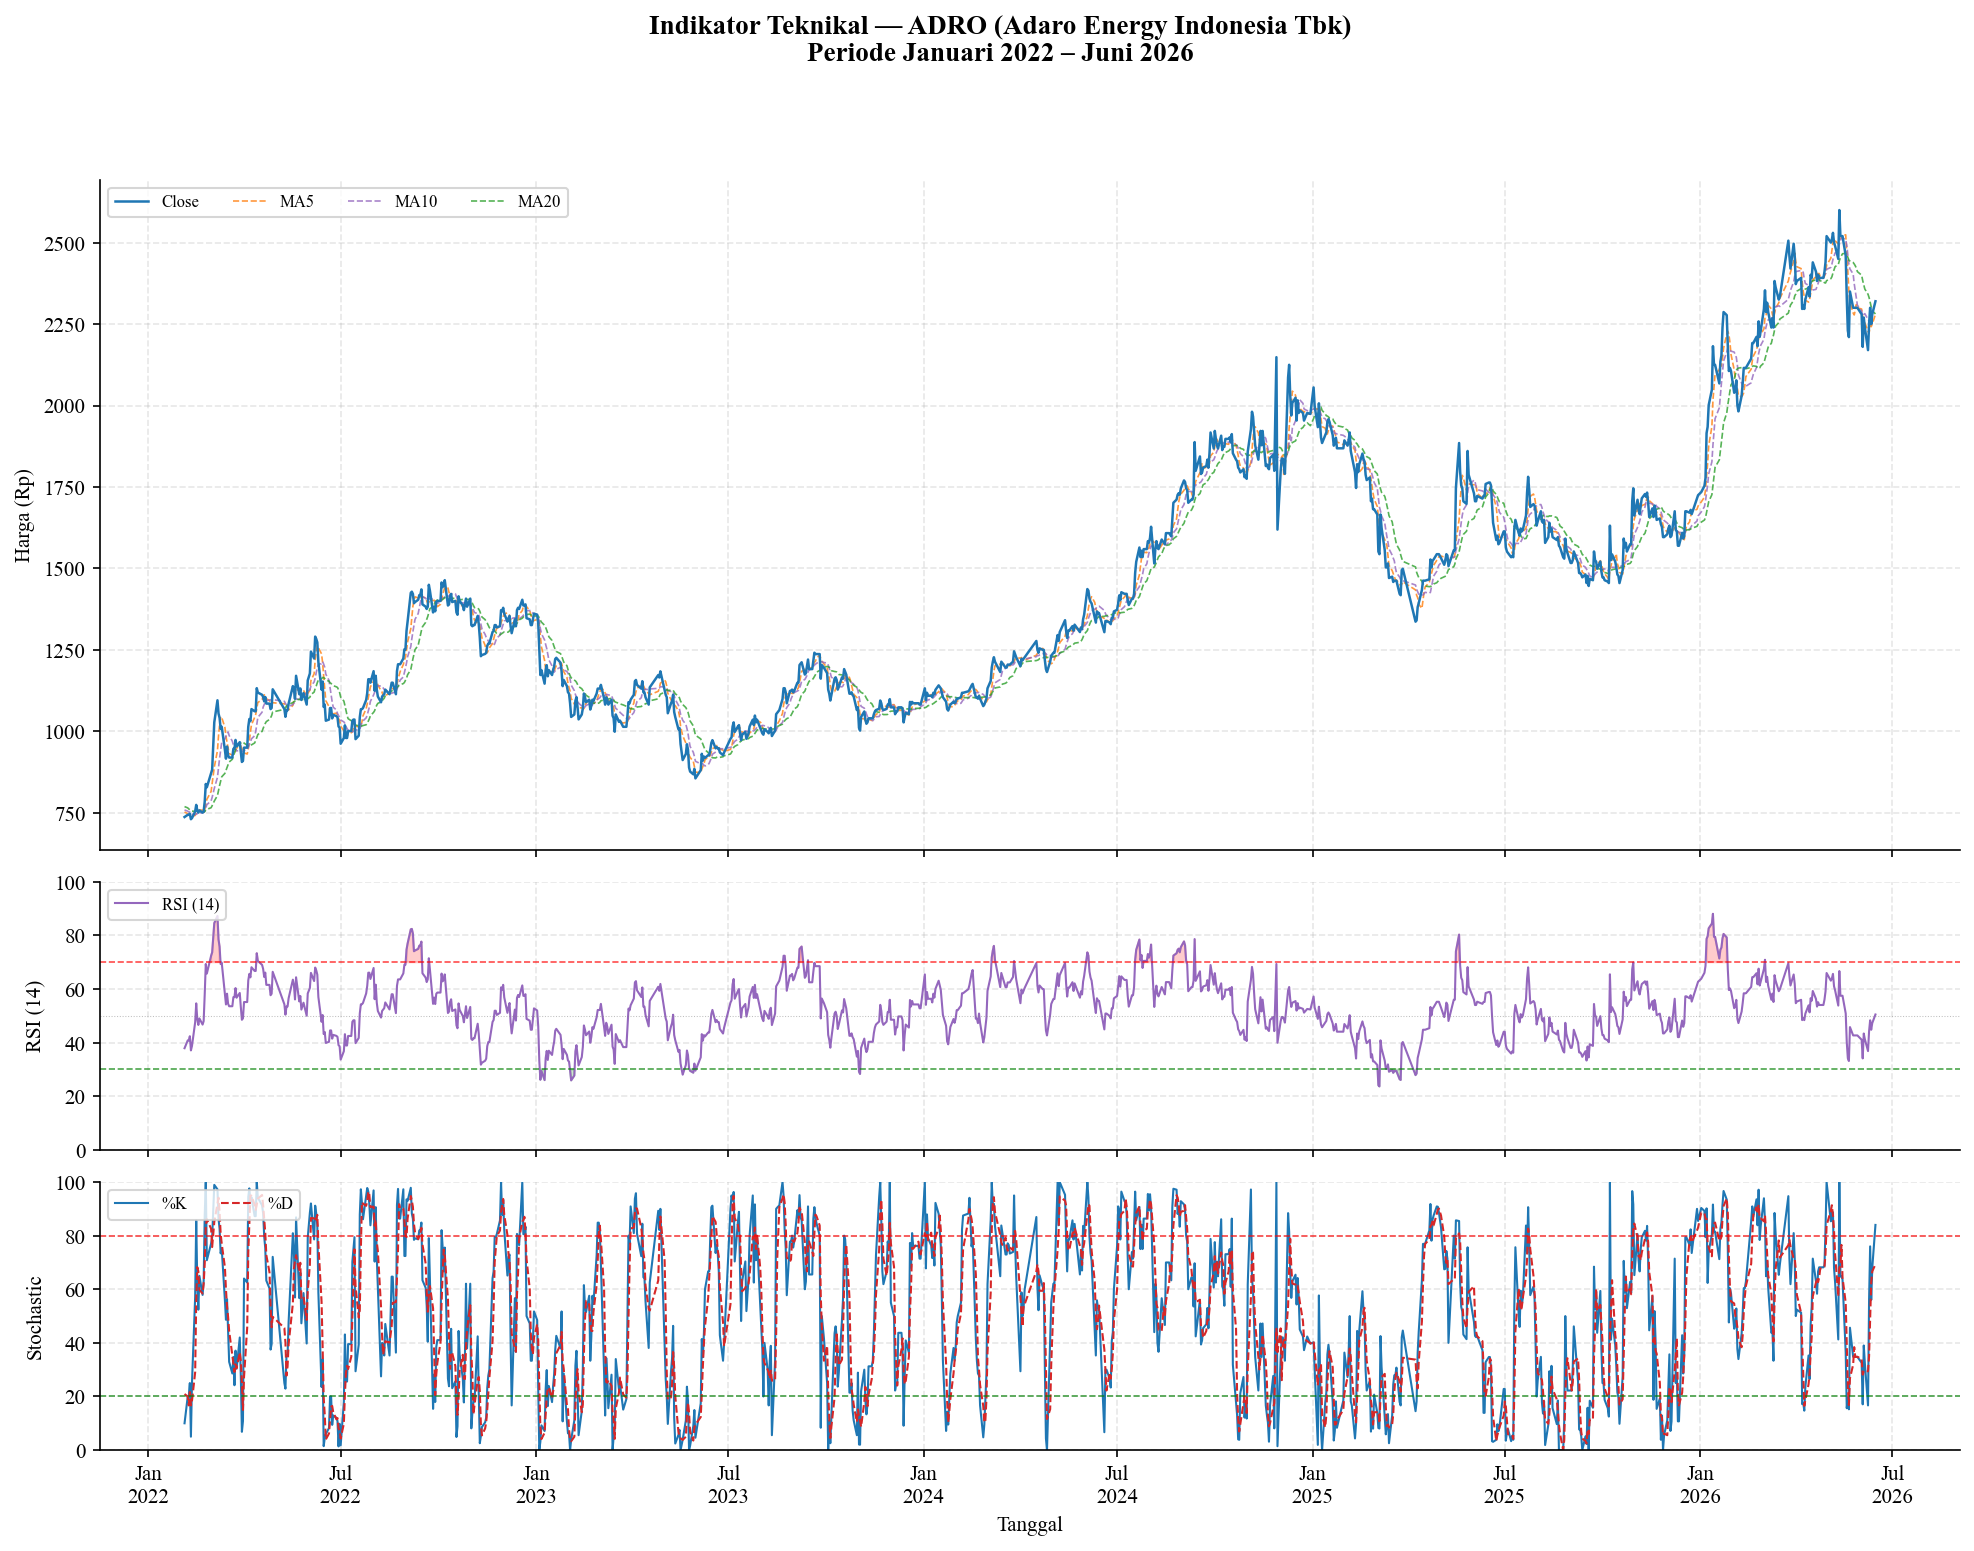

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_ADRO.png


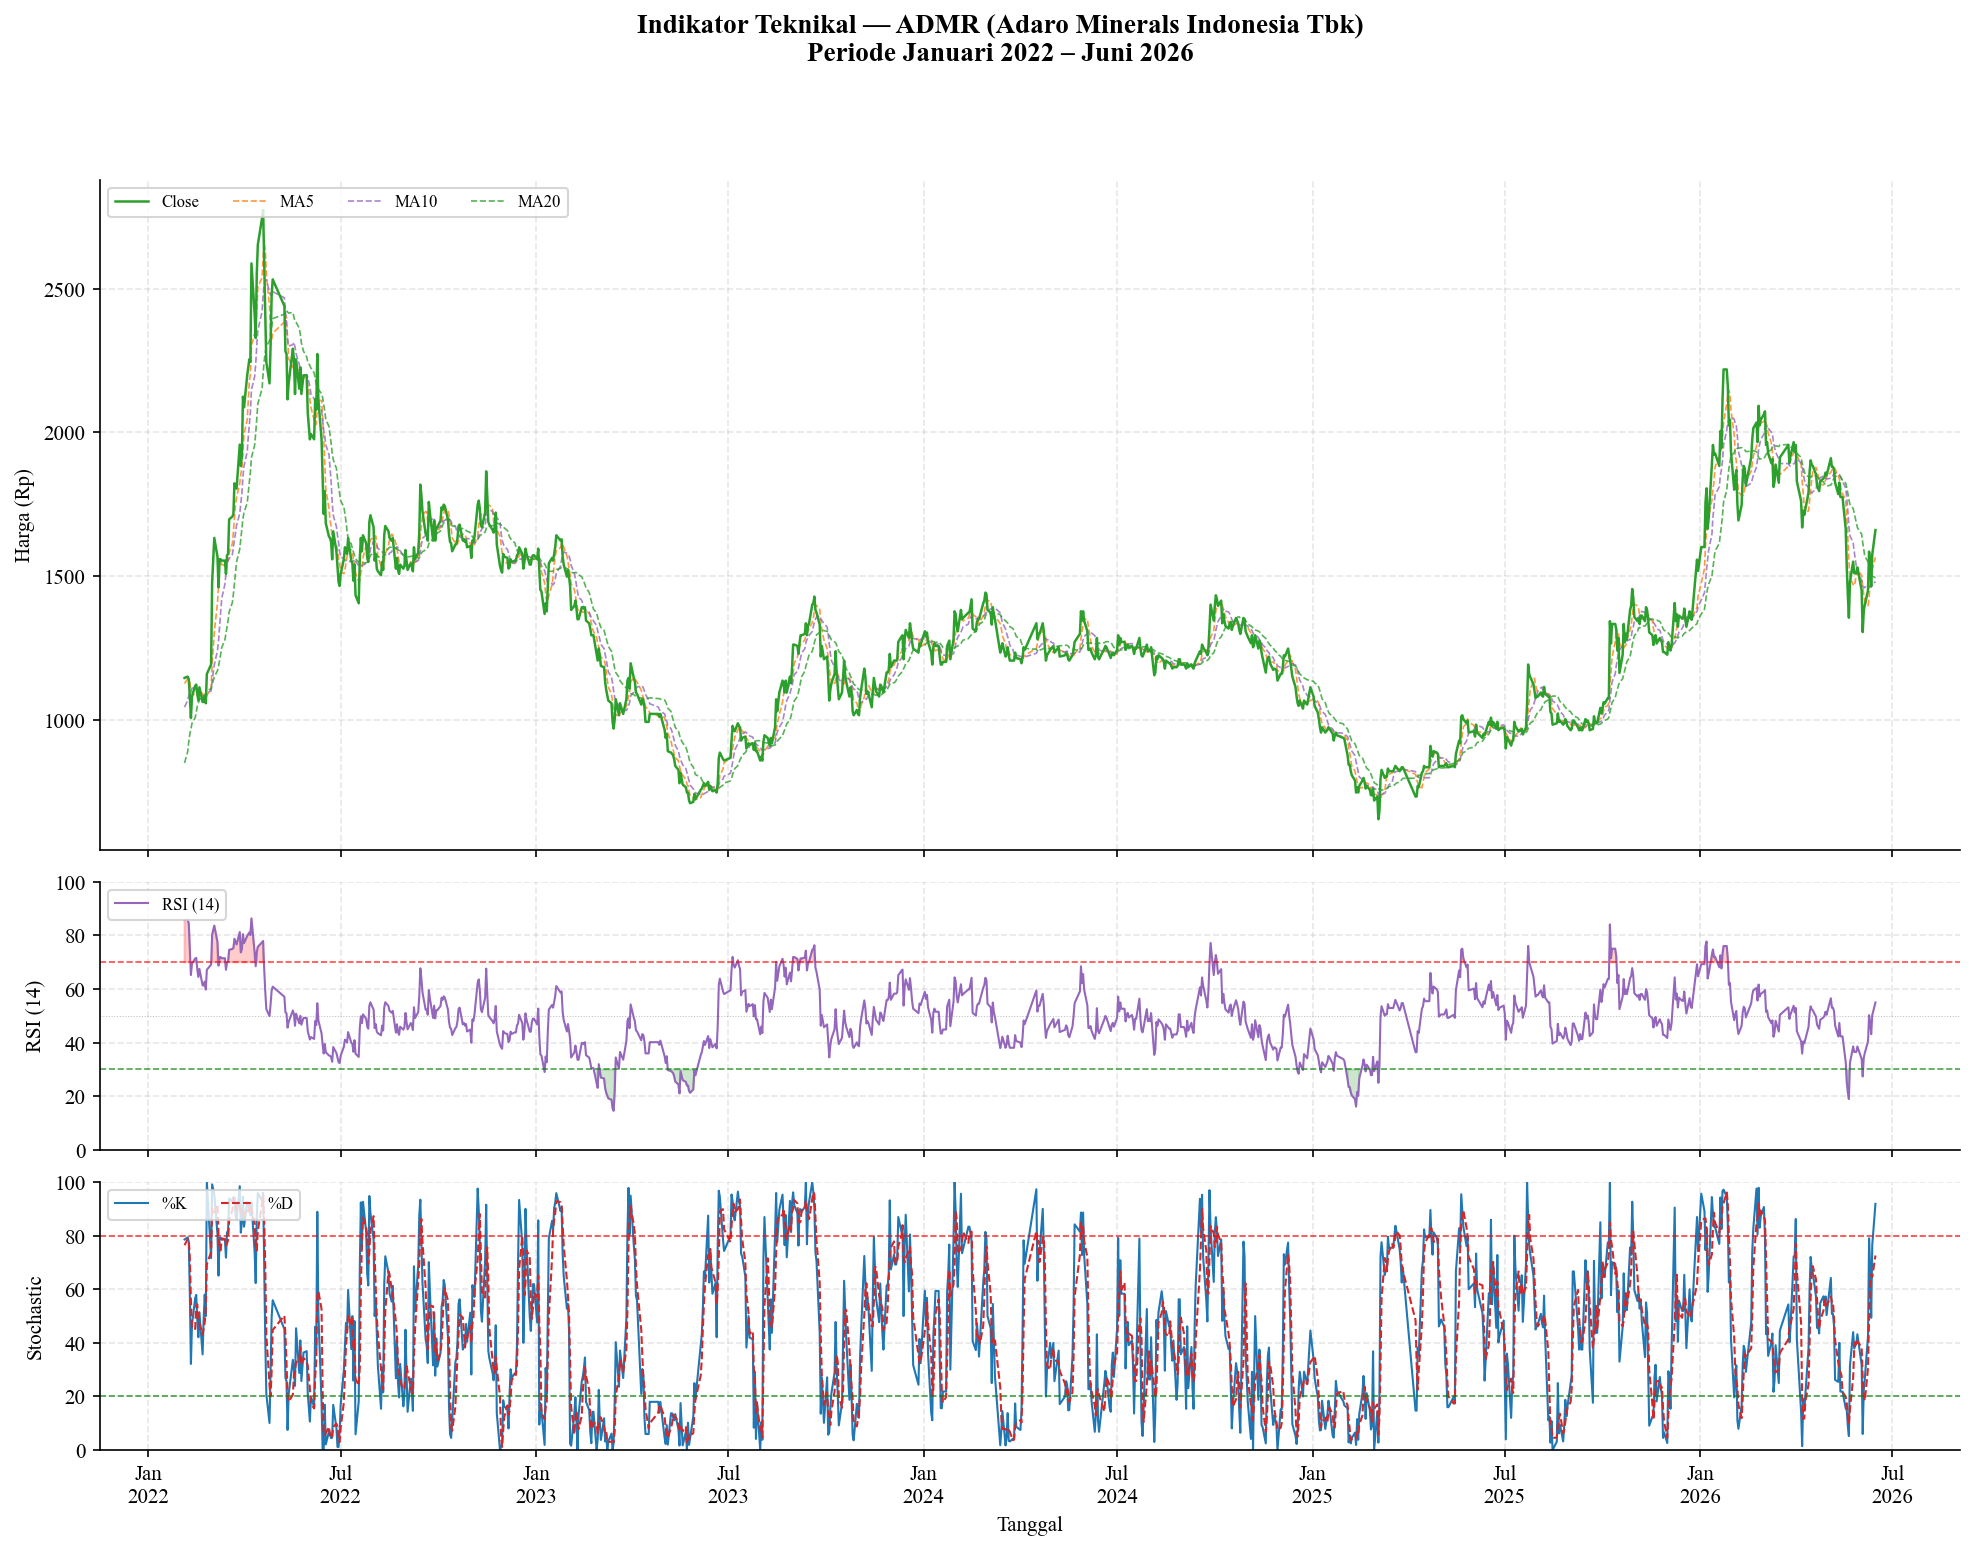

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_ADMR.png


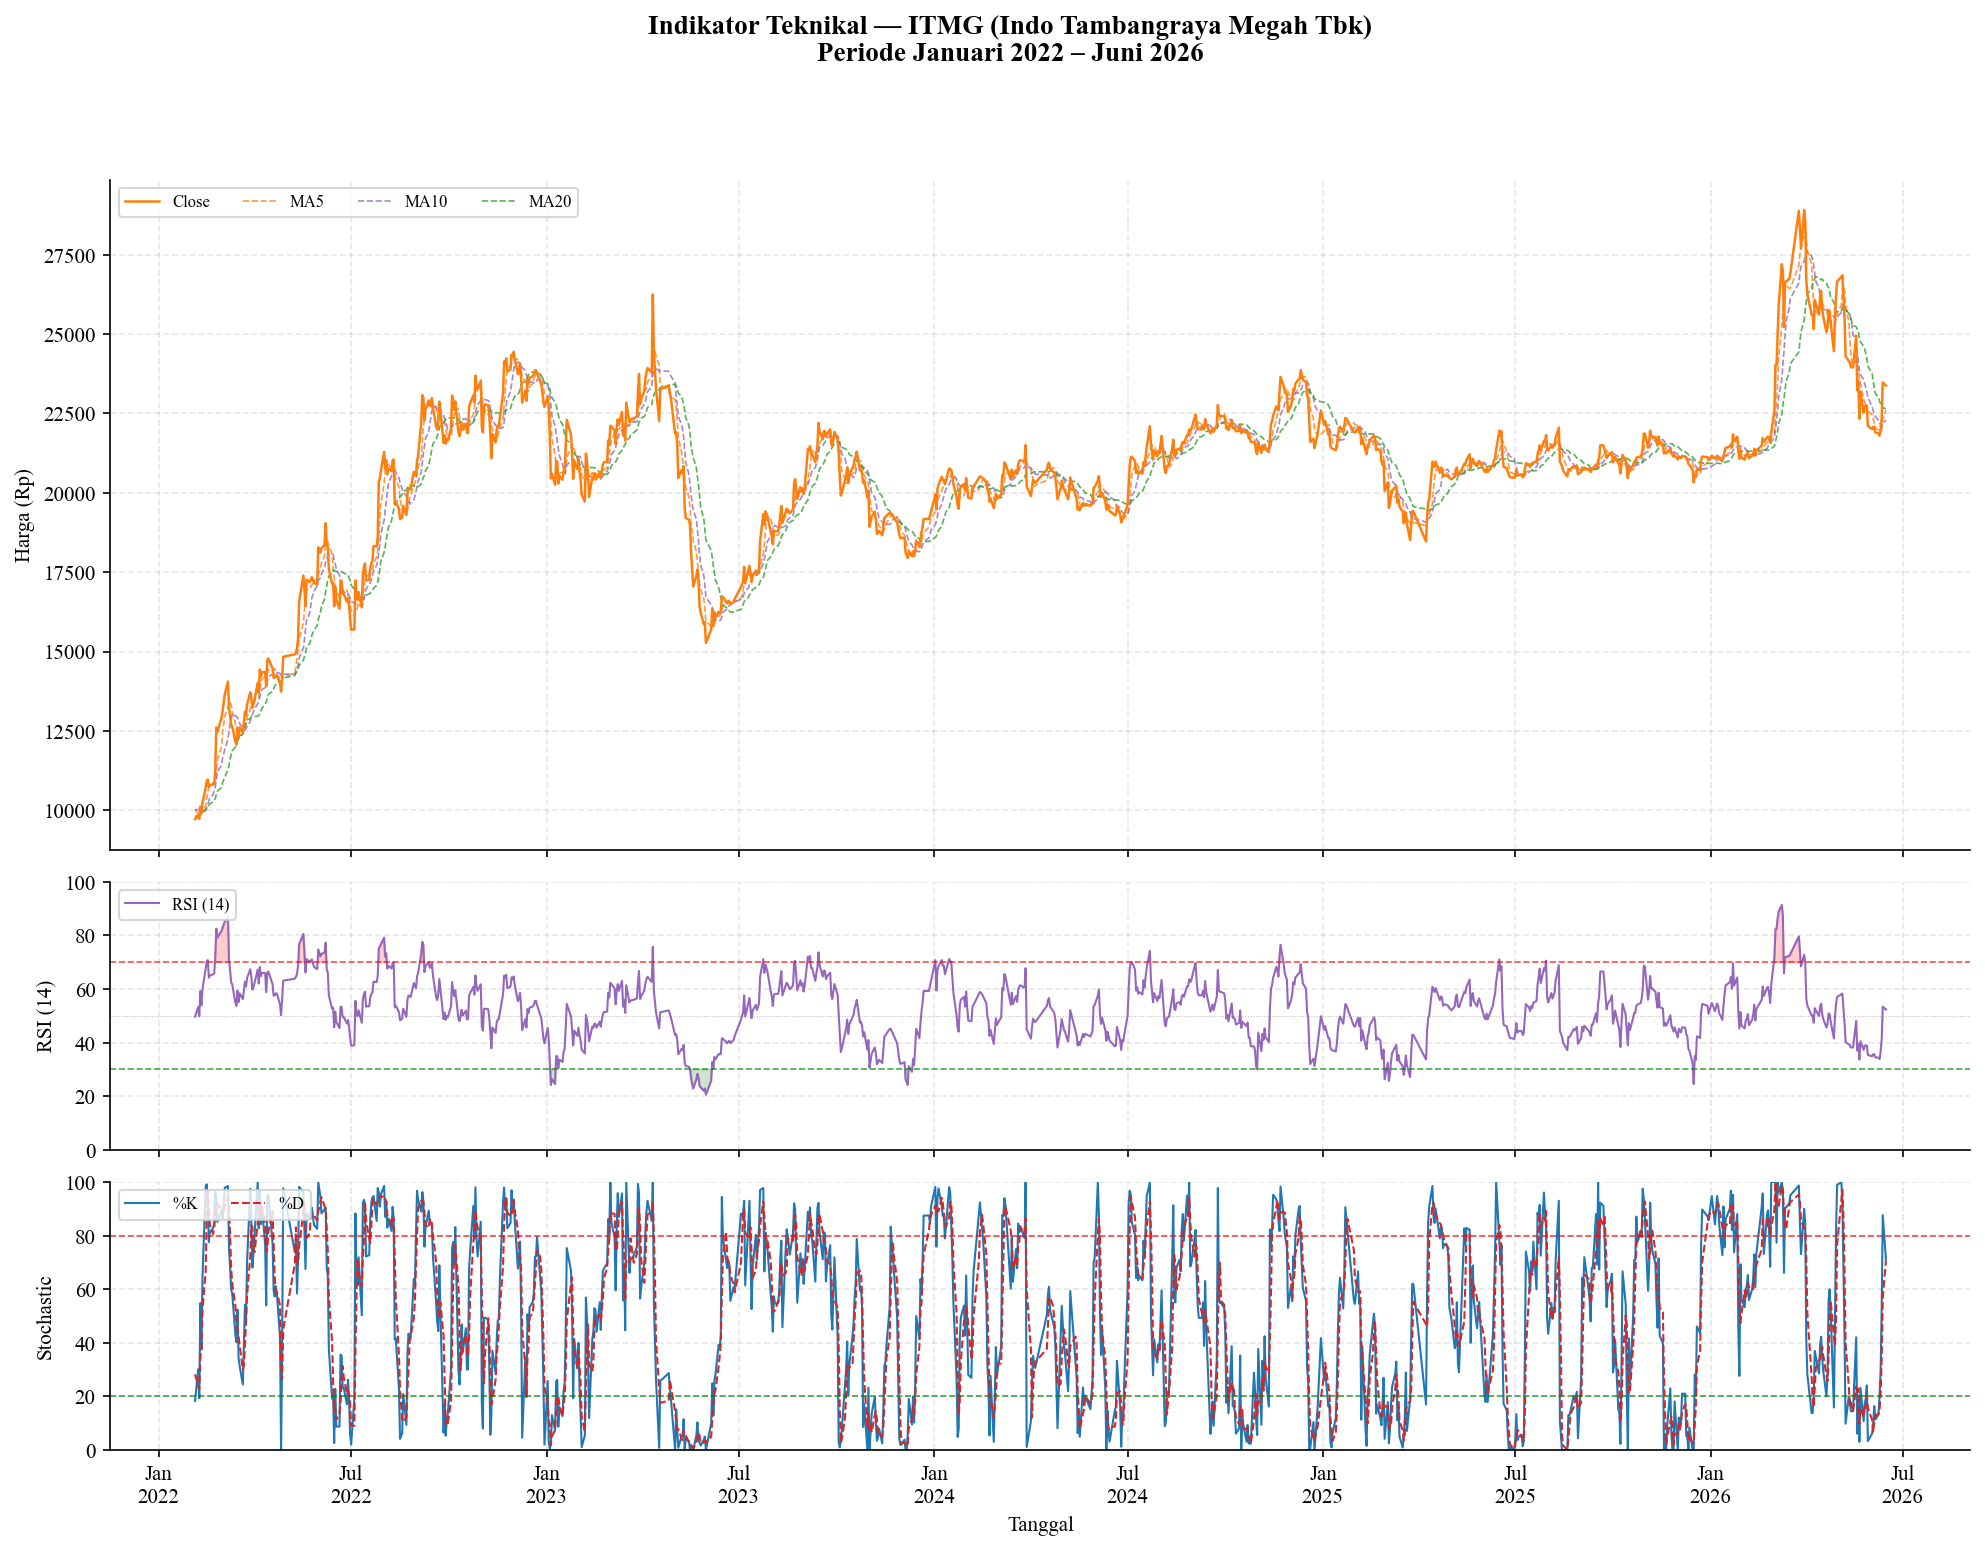

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_ITMG.png


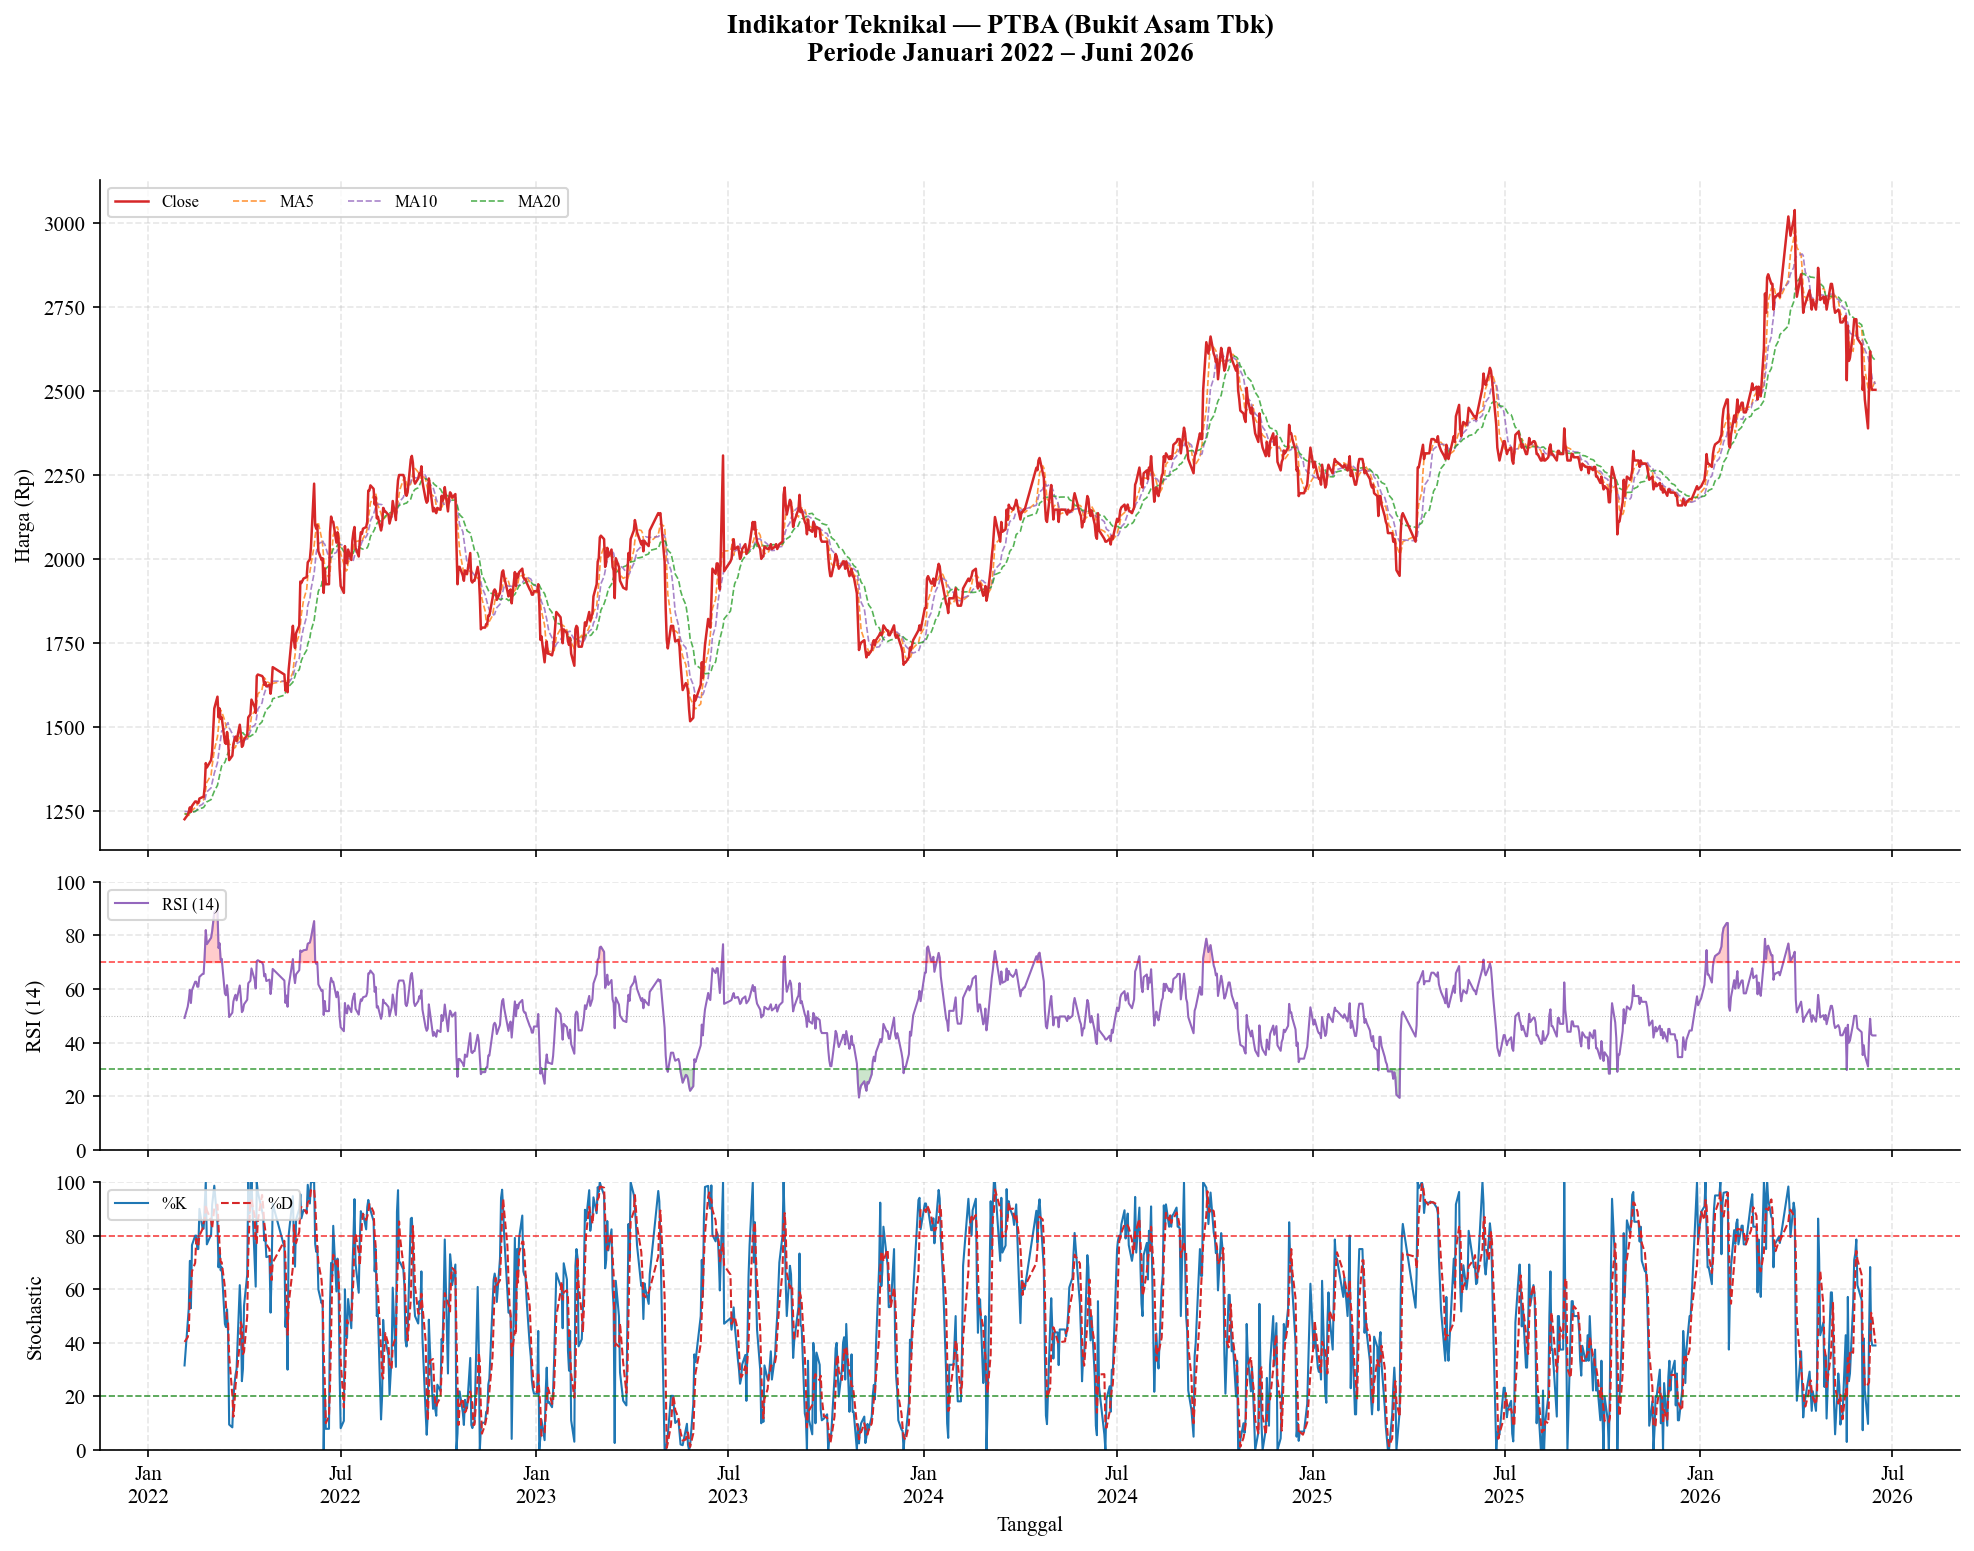

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_PTBA.png


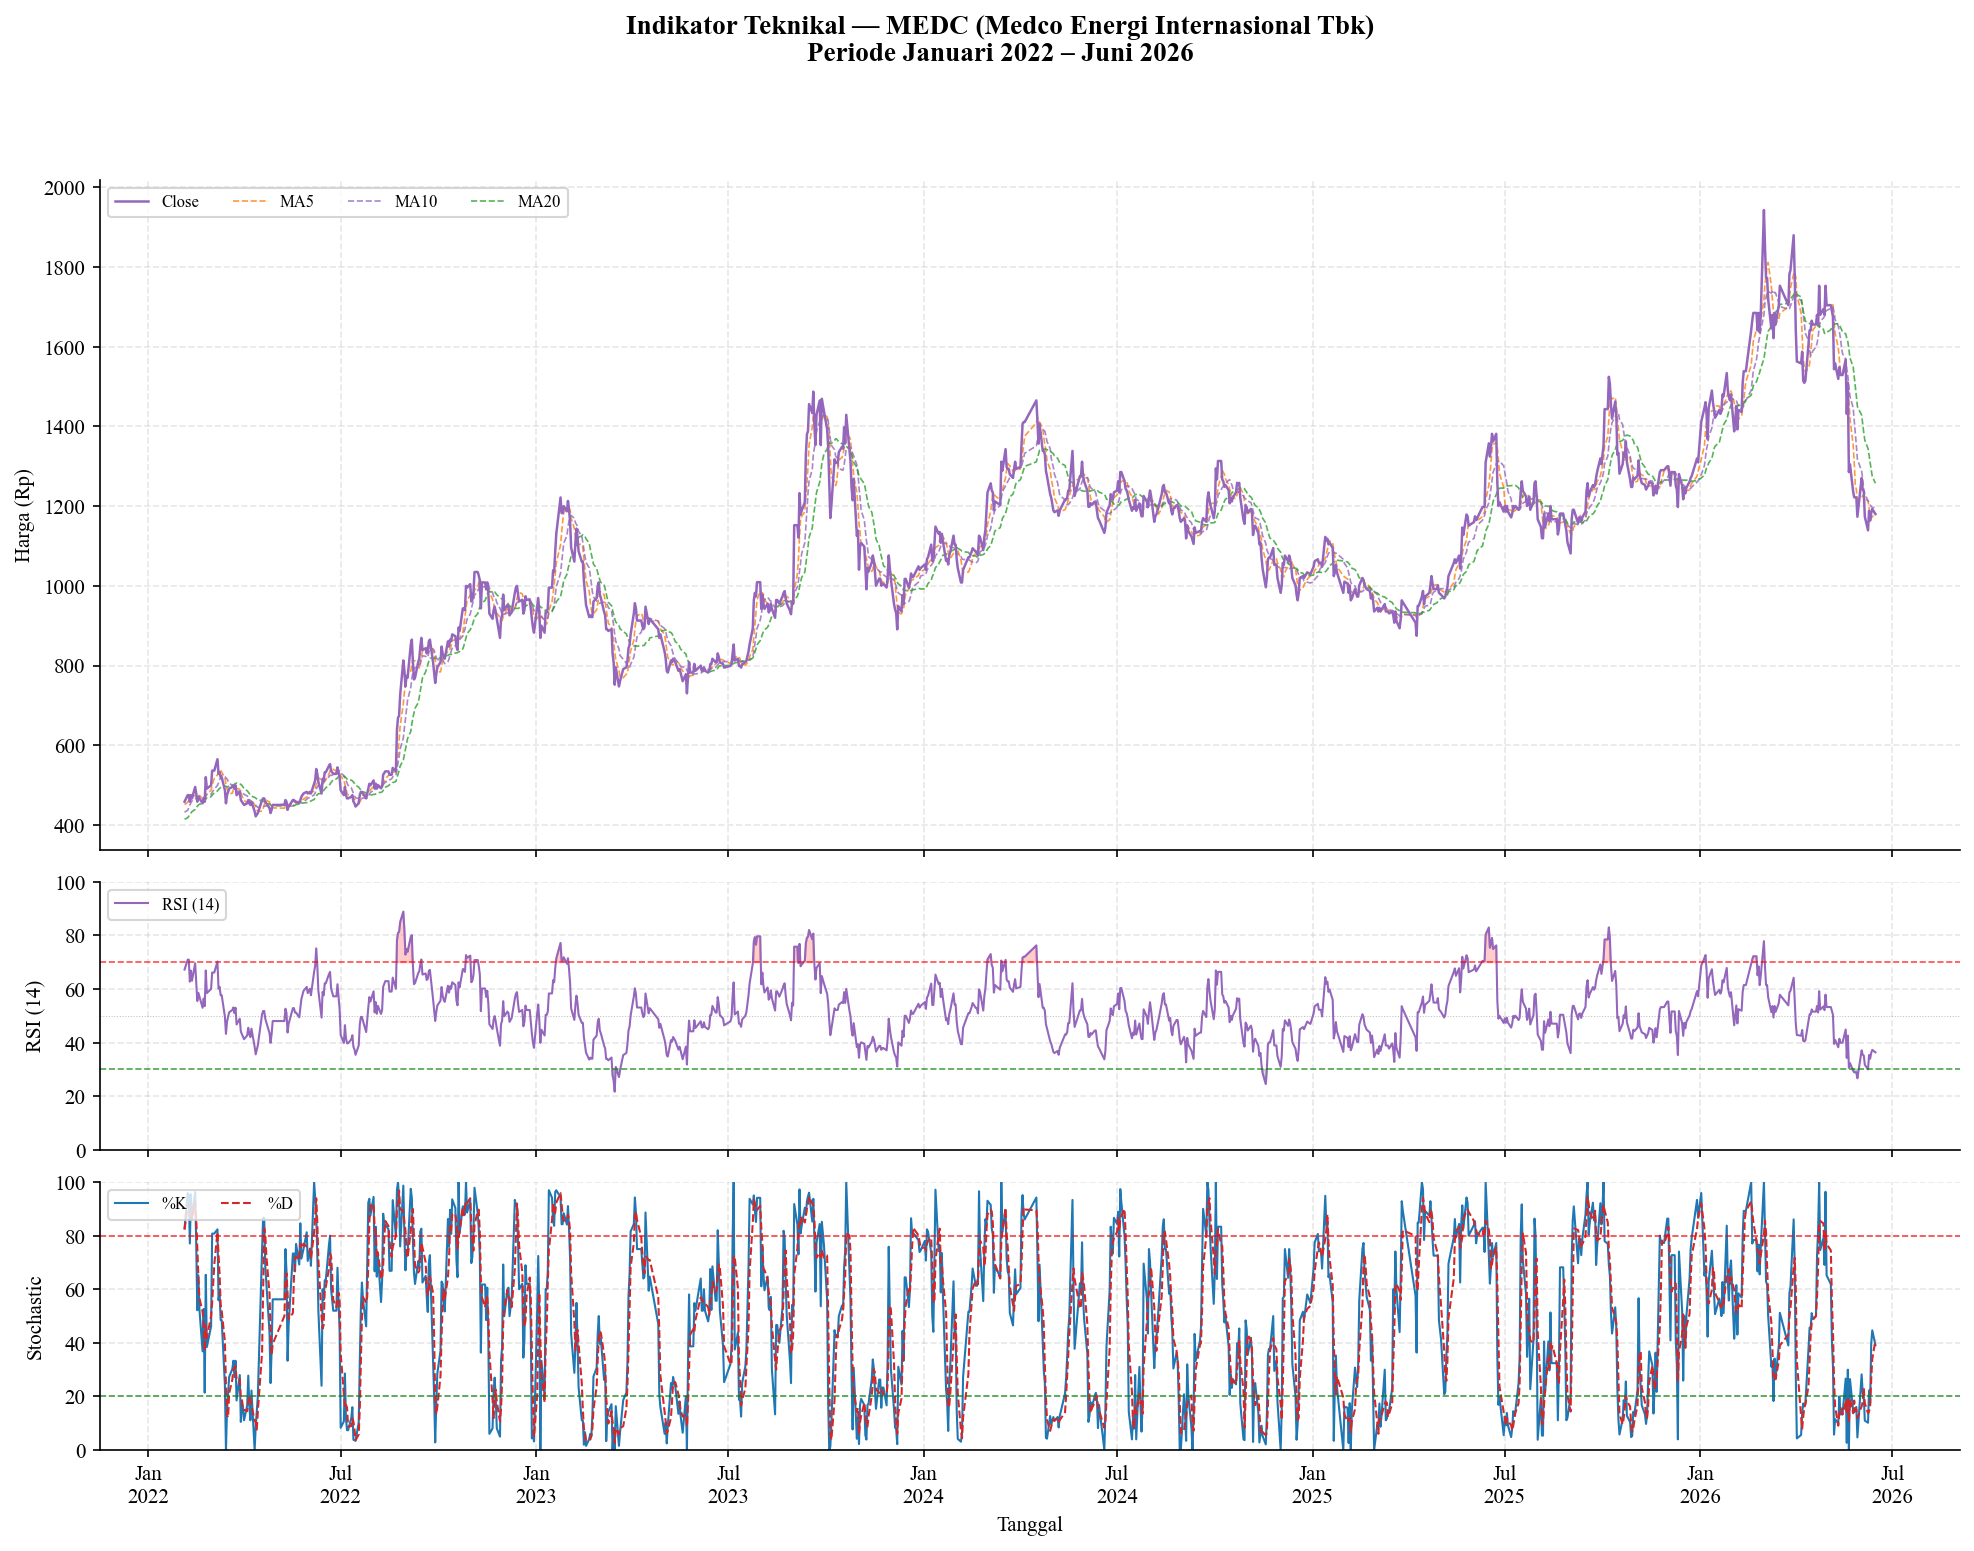

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_MEDC.png


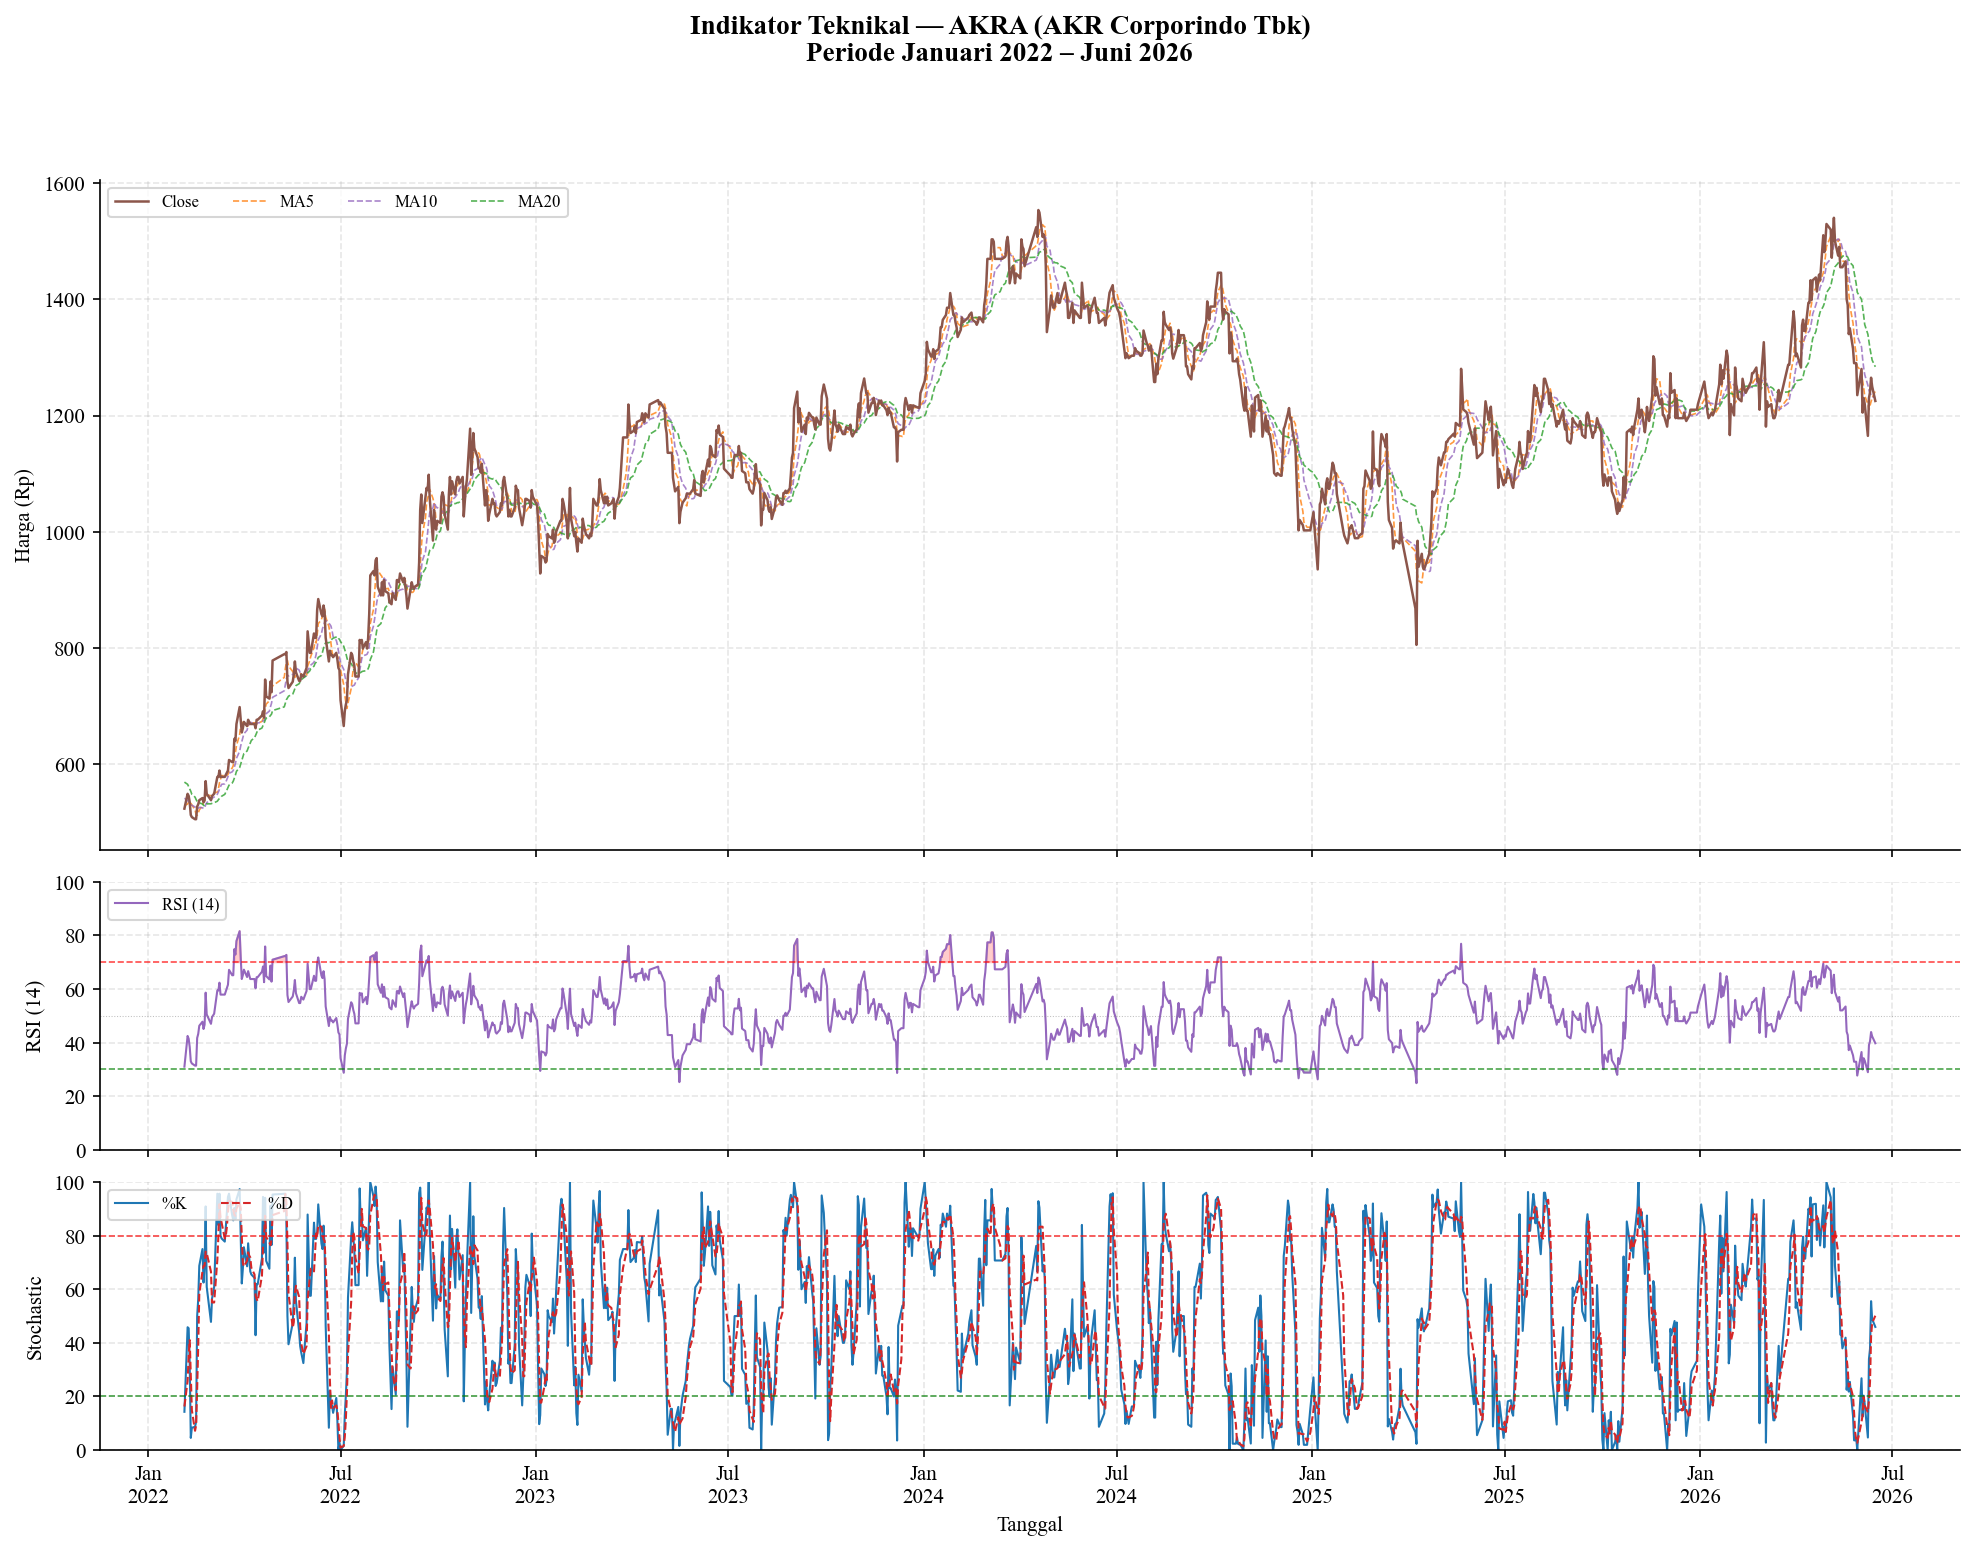

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_AKRA.png


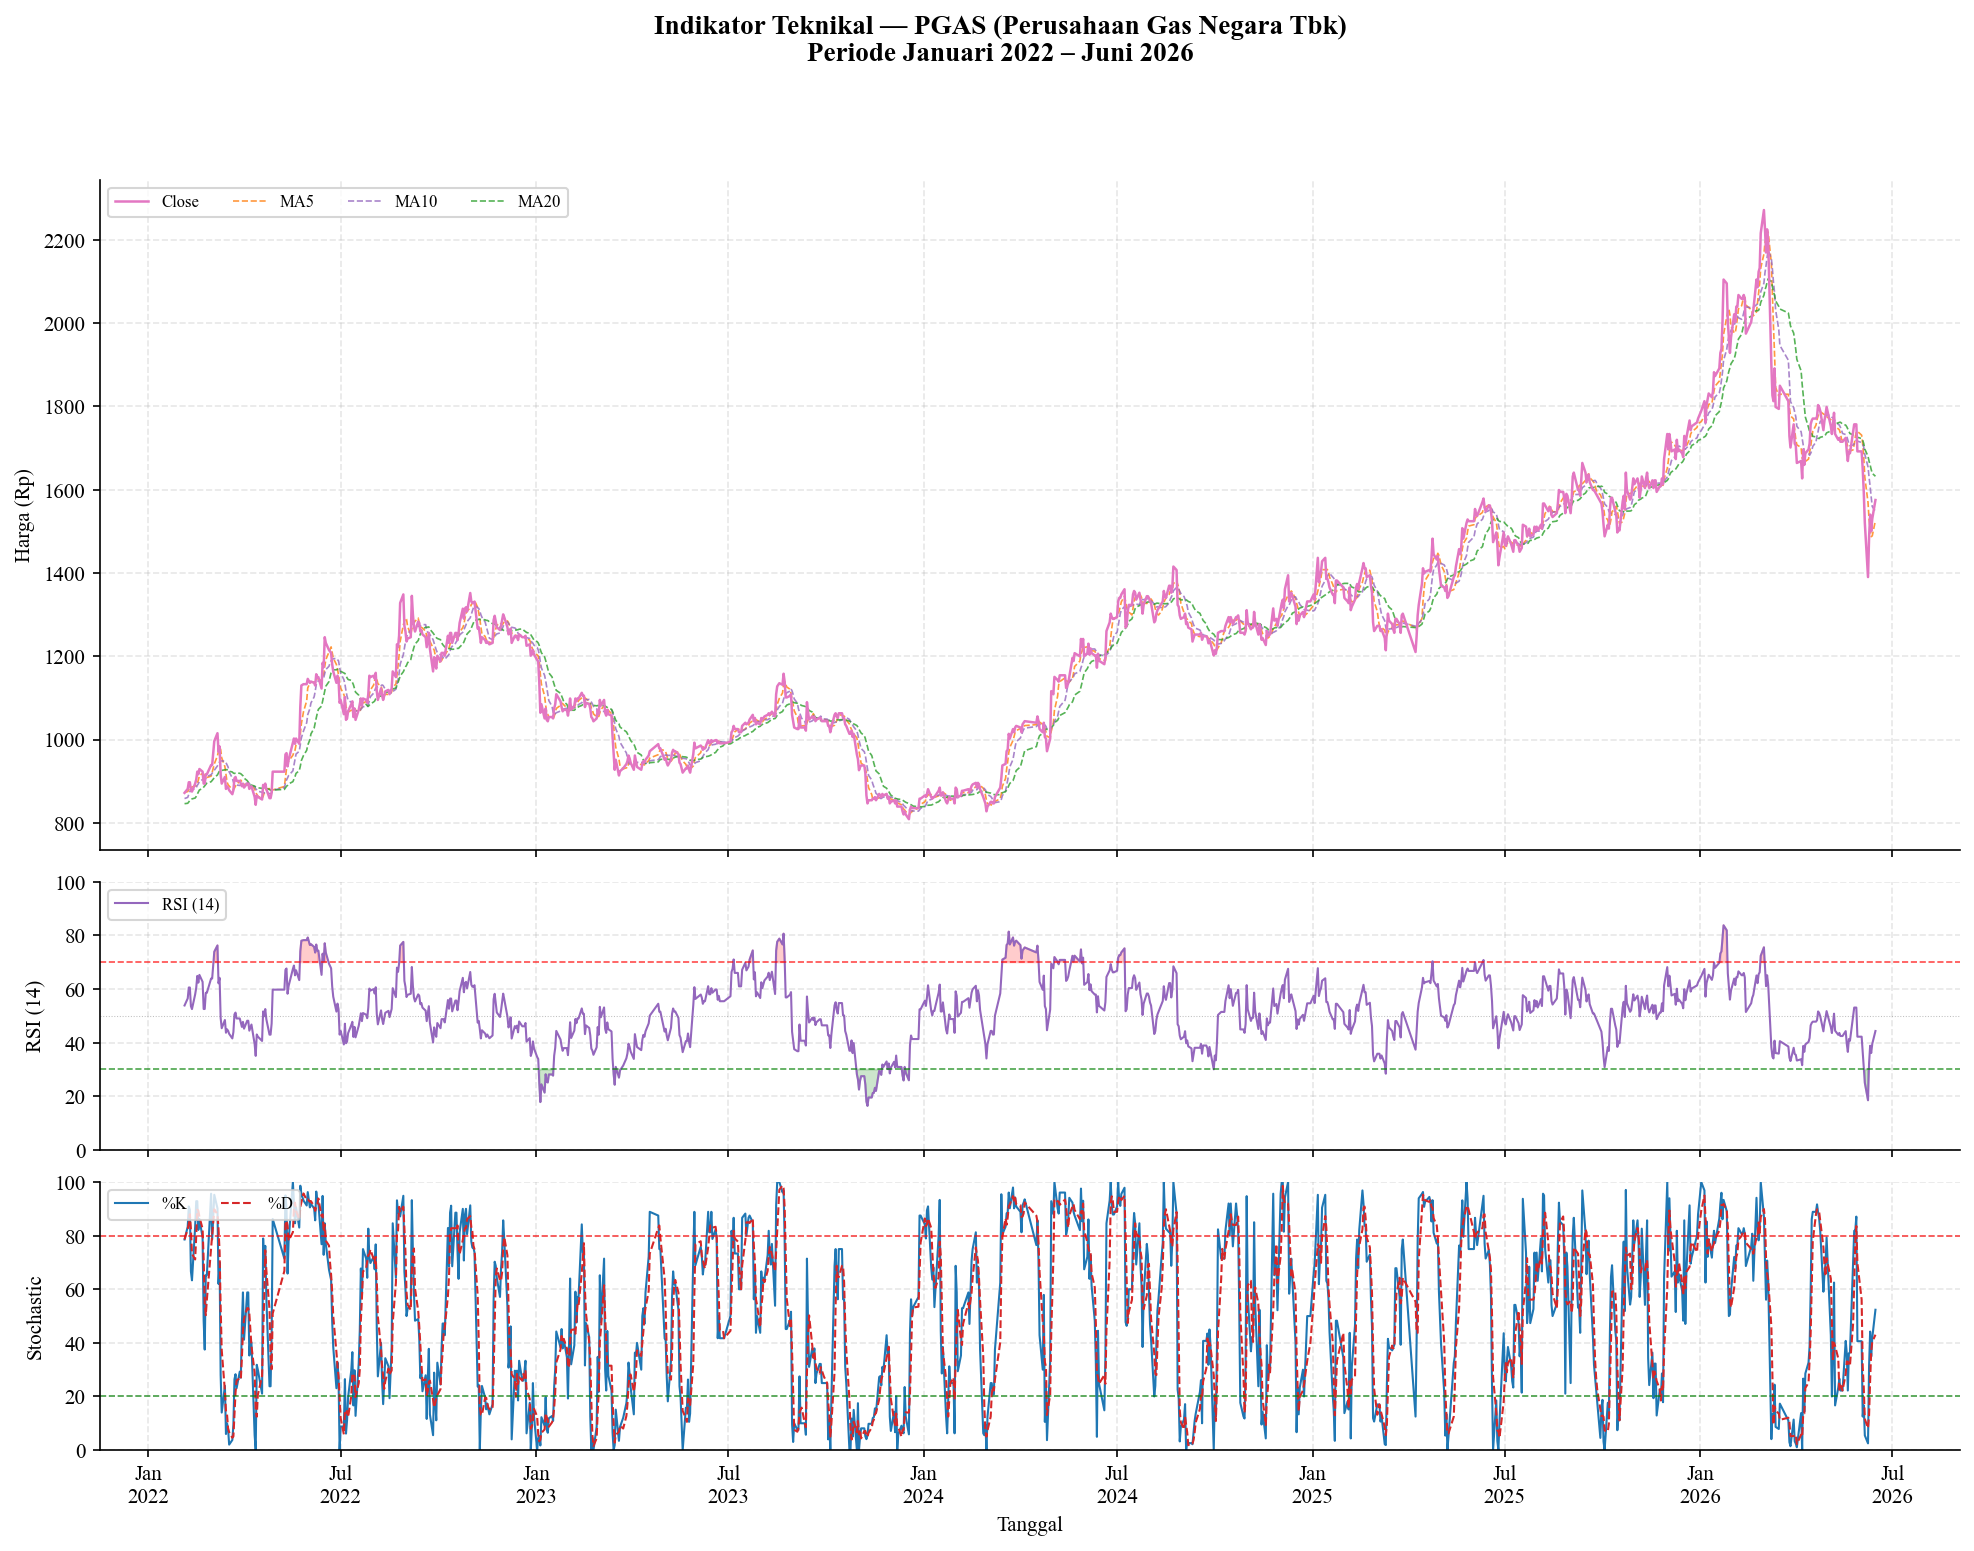

  ✅ Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\EDA\gambar_indikator_teknikal_PGAS.png


In [21]:
print('=' * 65)
print('  📊 VISUALISASI INDIKATOR TEKNIKAL PER EMITEN')
print('=' * 65)

import matplotlib.dates as mdates

for emiten in URUTAN_EMITEN:
    df_e = df_all[df_all['Emiten'] == emiten].copy()
    if df_e.empty:
        print(f'  ⚠️  {emiten}: Data kosong, skip')
        continue

    warna = WARNA_EMITEN.get(emiten, '#333333')
    nama  = NAMA_PERUSAHAAN.get(emiten, emiten)

    fig = plt.figure(figsize=(16, 11))
    fig.suptitle(
        f'Indikator Teknikal — {emiten} ({nama})\n'
        f'Periode Januari 2022 – Juni 2026',
        fontsize=13, fontweight='bold', y=0.98
    )

    gs = gridspec.GridSpec(3, 1, figure=fig,
                           height_ratios=[3, 1.2, 1.2],
                           hspace=0.08)

    ax1 = fig.add_subplot(gs[0])
    ax1.plot(df_e['Date'], df_e['Close'], color=warna, linewidth=1.2, label='Close', zorder=5)
    if 'MA5' in df_e.columns:
        ax1.plot(df_e['Date'], df_e['MA5'], color='#ff7f0e', linewidth=0.8, linestyle='--', label='MA5', alpha=0.8)
    if 'MA10' in df_e.columns:
        ax1.plot(df_e['Date'], df_e['MA10'], color='#9467bd', linewidth=0.8, linestyle='--', label='MA10', alpha=0.8)
    if 'MA20' in df_e.columns:
        ax1.plot(df_e['Date'], df_e['MA20'], color='#2ca02c', linewidth=0.8, linestyle='--', label='MA20', alpha=0.8)
    ax1.set_ylabel('Harga (Rp)', fontsize=10)
    ax1.legend(loc='upper left', fontsize=8, ncol=4)
    ax1.grid(alpha=0.3, linestyle='--')
    ax1.spines[['top','right']].set_visible(False)
    ax1.tick_params(labelbottom=False)

    ax2 = fig.add_subplot(gs[1], sharex=ax1)
    if 'RSI14' in df_e.columns:
        ax2.plot(df_e['Date'], df_e['RSI14'], color='#9467bd', linewidth=1.0, label='RSI (14)')
        ax2.axhline(70, color='red', linewidth=0.8, linestyle='--', alpha=0.7)
        ax2.axhline(30, color='green', linewidth=0.8, linestyle='--', alpha=0.7)
        ax2.axhline(50, color='gray', linewidth=0.5, linestyle=':', alpha=0.5)
        ax2.fill_between(df_e['Date'], df_e['RSI14'], 70, where=df_e['RSI14'] >= 70, alpha=0.2, color='red')
        ax2.fill_between(df_e['Date'], df_e['RSI14'], 30, where=df_e['RSI14'] <= 30, alpha=0.2, color='green')
        ax2.set_ylim(0, 100)
    ax2.set_ylabel('RSI (14)', fontsize=10)
    ax2.legend(loc='upper left', fontsize=8)
    ax2.grid(alpha=0.3, linestyle='--')
    ax2.spines[['top','right']].set_visible(False)
    ax2.tick_params(labelbottom=False)

    ax3 = fig.add_subplot(gs[2], sharex=ax1)
    if 'Stoch_K' in df_e.columns and 'Stoch_D' in df_e.columns:
        ax3.plot(df_e['Date'], df_e['Stoch_K'], color='#1f77b4', linewidth=1.0, label='%K')
        ax3.plot(df_e['Date'], df_e['Stoch_D'], color='#d62728', linewidth=1.0, linestyle='--', label='%D')
        ax3.axhline(80, color='red', linewidth=0.8, linestyle='--', alpha=0.7)
        ax3.axhline(20, color='green', linewidth=0.8, linestyle='--', alpha=0.7)
        ax3.set_ylim(0, 100)
    ax3.set_ylabel('Stochastic', fontsize=10)
    ax3.set_xlabel('Tanggal', fontsize=10)
    ax3.legend(loc='upper left', fontsize=8, ncol=2)
    ax3.grid(alpha=0.3, linestyle='--')
    ax3.spines[['top','right']].set_visible(False)

    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=6))

    plt.tight_layout(rect=[0, 0, 1, 0.96])

    path_gambar = DIR_GAMBAR / f'gambar_indikator_teknikal_{emiten}.png'
    plt.savefig(path_gambar, dpi=200, bbox_inches='tight')
    plt.show()
    print(f'  ✅ Gambar disimpan: {path_gambar}')
    plt.close()


---
## 💾 CELL 10 — Definisi X1 Final & Simpan Dataset Teknikal

Menyimpan **seluruh kolom** (termasuk kolom referensi Open/High/Low/Close/Volume/MA mentah untuk keperluan EDA Bab 4) ke `technical_features.csv`, TAPI menandai eksplisit daftar `KOLOM_X1_FINAL` mana yang boleh masuk X model di notebook modeling (XGBoost/LSTM) berikutnya.

⚠️ **PENTING untuk notebook modeling selanjutnya**: kolom `Volatilitas` (current-day, dipakai sbg basis lag) **BUKAN** fitur X — hanya `Volatilitas_Target` yang jadi Y.

In [22]:
print('=' * 65)
print('  💾 SIMPAN DATASET TEKNIKAL FINAL')
print('=' * 65)

KOLOM_X1_FINAL = [
    'Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14',
    'Stoch_K', 'Stoch_D', 'Volume_ZScore',
]
KOLOM_Y = 'Volatilitas_Target'
KOLOM_REFERENSI = ['Open', 'High', 'Low', 'Close', 'Volume',
                    'MA5', 'MA10', 'MA20', 'Volatilitas']
KOLOM_KUNCI = ['Date', 'Emiten']

print(f'X1 FINAL ({len(KOLOM_X1_FINAL)} fitur)  : {KOLOM_X1_FINAL}')
print(f'Y ({KOLOM_Y})')
print(f'Kolom referensi (bukan X, untuk EDA)  : {KOLOM_REFERENSI}')
print()

df_save = df_all.copy()
df_save['Date'] = pd.to_datetime(df_save['Date']).dt.strftime('%Y-%m-%d')

path_output = DIR_PROCESSED / 'technical_features.csv'
df_save.to_csv(path_output, index=False, encoding='utf-8-sig')

# ── simpan juga daftar X1/Y sbg metadata JSON, dipakai notebook modeling
import json as _json
path_meta = DIR_PROCESSED / 'technical_features_meta.json'
with open(path_meta, 'w', encoding='utf-8') as f:
    _json.dump({
        'kolom_x1': KOLOM_X1_FINAL,
        'kolom_y': KOLOM_Y,
        'kolom_referensi': KOLOM_REFERENSI,
        'kolom_kunci': KOLOM_KUNCI,
    }, f, ensure_ascii=False, indent=2)

print(f'SAVE PATH        : {path_output.resolve()}')
print(f'METADATA X1/Y    : {path_meta.resolve()}')
print(f'Total baris      : {len(df_save):,}')
print(f'Total kolom      : {len(df_save.columns)}')

# VALIDASI RELOAD
cek = pd.read_csv(path_output)
print('\nKolom hasil reload:')
print(cek.columns.tolist())


  💾 SIMPAN DATASET TEKNIKAL FINAL
X1 FINAL (13 fitur)  : ['Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5', 'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14', 'Stoch_K', 'Stoch_D', 'Volume_ZScore']
Y (Volatilitas_Target)
Kolom referensi (bukan X, untuk EDA)  : ['Open', 'High', 'Low', 'Close', 'Volume', 'MA5', 'MA10', 'MA20', 'Volatilitas']

SAVE PATH        : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features.csv
METADATA X1/Y    : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features_meta.json
Total baris      : 7,287
Total kolom      : 25

Kolom hasil reload:
['Date', 'Emiten', 'Open', 'Close', 'High', 'Low', 'Volume', 'Log_Return', 'Volatilitas', 'Volatilitas_Target', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5', 'MA5', 'MA10', '

In [23]:
import numpy as np

# ══ 0. URUTKAN: per emiten, lalu per tanggal (WAJIB sebelum rolling apa pun) ══
df_harga = df_harga.sort_values(['Emiten', 'Date']).reset_index(drop=True)

def per_emiten(kolom):
    """Helper: groupby segar agar kolom baru ikut dikenali."""
    return df_harga.groupby('Emiten')[kolom]

# ══ 1. RETURN & VOLATILITAS ══
df_harga['Log_Return']  = per_emiten('Close').transform(lambda s: np.log(s / s.shift(1)))
df_harga['Volatilitas'] = per_emiten('Log_Return').transform(
    lambda s: s.rolling(20, min_periods=20).std())
df_harga['Volatilitas_Target'] = per_emiten('Volatilitas').shift(-1)   # forecast t+1

# ══ 2. FITUR AUTOREGRESIF VOLATILITAS ══
for k in (1, 2, 3):
    df_harga[f'Vol_Lag{k}'] = per_emiten('Volatilitas').shift(k)
df_harga['Vol_MA5']  = per_emiten('Volatilitas').transform(lambda s: s.rolling(5).mean())
df_harga['Vol_STD5'] = per_emiten('Volatilitas').transform(lambda s: s.rolling(5).std())

# ══ 3. MOVING AVERAGE & RASIO ══
for n in (5, 10, 20):
    df_harga[f'MA{n}'] = per_emiten('Close').transform(lambda s: s.rolling(n).mean())
    df_harga[f'MA{n}_Ratio'] = df_harga['Close'] / df_harga[f'MA{n}'] - 1

# ══ 4. RSI-14 (Wilder's smoothing, per emiten) ══
def hitung_rsi_wilder(close, periode=14):
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/periode, min_periods=periode, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1/periode, min_periods=periode, adjust=False).mean()
    rs = avg_gain / avg_loss.replace(0, np.nan)
    rsi = 100 - 100 / (1 + rs)
    rsi = rsi.where(avg_loss != 0, 100.0)                       # loss=0 → RSI 100
    rsi = rsi.where(~((avg_gain == 0) & (avg_loss == 0)), 50.0) # datar → netral 50
    return rsi

df_harga['RSI14'] = per_emiten('Close').transform(hitung_rsi_wilder)

# ══ 5. STOCHASTIC %K / %D ══
low14  = per_emiten('Low').transform(lambda s: s.rolling(14, min_periods=14).min())
high14 = per_emiten('High').transform(lambda s: s.rolling(14, min_periods=14).max())
rentang = (high14 - low14).replace(0, np.nan)
df_harga['Stoch_K'] = (df_harga['Close'] - low14) / rentang * 100
df_harga['Stoch_D'] = per_emiten('Stoch_K').transform(lambda s: s.rolling(3).mean())

# ══ 6. VOLUME Z-SCORE ══
vol_mean = per_emiten('Volume').transform(lambda s: s.rolling(20, min_periods=20).mean())
vol_std  = per_emiten('Volume').transform(lambda s: s.rolling(20, min_periods=20).std())
df_harga['Volume_ZScore'] = (df_harga['Volume'] - vol_mean) / vol_std.replace(0, np.nan)

# ══ 7. VALIDASI WAJIB ══
sk  = df_harga['Stoch_K'].dropna()
rsi = df_harga['RSI14'].dropna()
assert sk.between(0, 100).all(),  f'Stoch_K keluar 0–100! min={sk.min():.2f} max={sk.max():.2f}'
assert rsi.between(0, 100).all(), f'RSI keluar 0–100! min={rsi.min():.2f} max={rsi.max():.2f}'
assert df_harga['Log_Return'].abs().max() < 0.5, 'Return ekstrem — indikasi kebocoran antar-emiten!'
baris_pertama = df_harga.groupby('Emiten').head(1).index
assert df_harga.loc[baris_pertama, 'Log_Return'].isna().all(), \
    'Log_Return baris pertama emiten tidak NaN — sort/groupby bermasalah!'
print('✅ VALIDASI LOLOS')
print(f'   Stoch_K : [{sk.min():.2f}, {sk.max():.2f}]  |  RSI14 : [{rsi.min():.2f}, {rsi.max():.2f}]')
print(f'   |Log_Return| maks : {df_harga["Log_Return"].abs().max():.4f}')
print(df_harga.groupby("Emiten")[["Stoch_K","RSI14"]].agg(["min","max"]).round(2))

✅ VALIDASI LOLOS
   Stoch_K : [0.00, 100.00]  |  RSI14 : [14.59, 97.47]
   |Log_Return| maks : 0.2987
       Stoch_K         RSI14       
           min    max    min    max
Emiten                             
ADMR       0.0  100.0  14.59  97.47
ADRO       0.0  100.0  15.35  84.10
AKRA       0.0  100.0  16.79  81.13
ITMG       0.0  100.0  17.14  91.32
MEDC       0.0  100.0  21.74  87.60
PGAS       0.0  100.0  15.60  83.79
PTBA       0.0  100.0  19.41  89.97


In [24]:
# ==============================================================================
# CELL — TABEL CONTOH HASIL CELL 3 (FITUR DASAR) — SAMPEL PERTENGAHAN
# (Log Return, Volatilitas+Target, MA/Rasio, Stochastic)
# ==============================================================================
import pandas as pd

EMITEN_CONTOH = 'PTBA'   # Ganti kode di sini bila ingin contoh emiten lain
N_BARIS       = 10       # Jumlah baris yang ditampilkan (kontinu, dari tengah)

df_contoh = dict_fitur[EMITEN_CONTOH].copy()

# ── Ambil N baris kontinu di sekitar PERTENGAHAN rentang data ───────────────
def ambil_tengah(df, n=10):
    total = len(df)
    tengah = total // 2
    mulai = max(0, tengah - n // 2)
    selesai = min(total, mulai + n)
    return df.iloc[mulai:selesai].copy()

# ── 1. TABEL A — LOG RETURN & VOLATILITAS (+TARGET) ─────────────────────────
kolom_a = ['Date', 'Log_Return', 'Volatilitas', 'Volatilitas_Target',
           'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5']
tabel_a_raw = df_contoh[kolom_a].copy()
tabel_a_raw['Date'] = pd.to_datetime(tabel_a_raw['Date']).dt.strftime('%d/%m/%Y')
tabel_a = ambil_tengah(tabel_a_raw, N_BARIS).reset_index(drop=True)

FILE_TABEL_A = f'tabel_contoh_log_return_volatilitas_{EMITEN_CONTOH}_tengah.csv'
PATH_TABEL_A = DIR_TABEL / FILE_TABEL_A
tabel_a_raw.to_csv(PATH_TABEL_A, index=False, encoding='utf-8-sig')   # tetap simpan versi lengkap mentah

tabel_a_tampil = tabel_a.copy()
kolom_angka_a = kolom_a[1:]
for kol in kolom_angka_a:
    tabel_a_tampil[kol] = tabel_a_tampil[kol].apply(
        lambda x: '–' if pd.isna(x)
        else f'{x:,.6f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
    )
tabel_a_tampil.index = tabel_a_tampil.index + 1
tabel_a_tampil.index.name = 'No'

print('=' * 90)
print(f' Tabel A. Contoh Log Return & Volatilitas — Sampel Pertengahan Periode')
print(f' Emiten: {EMITEN_CONTOH} — {NAMA_PERUSAHAAN[EMITEN_CONTOH]}')
print(f' Rentang tanggal sampel: {tabel_a_tampil["Date"].iloc[0]} s/d {tabel_a_tampil["Date"].iloc[-1]}')
print('-' * 90)
display(tabel_a_tampil)

# ── 2. TABEL B — MOVING AVERAGE/RASIO & STOCHASTIC OSCILLATOR ──────────────
kolom_b = ['Date', 'Close', 'MA5', 'MA10', 'MA20',
           'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'Stoch_K', 'Stoch_D']
tabel_b_raw = df_contoh[kolom_b].copy()
tabel_b_raw['Date'] = pd.to_datetime(tabel_b_raw['Date']).dt.strftime('%d/%m/%Y')
tabel_b = ambil_tengah(tabel_b_raw, N_BARIS).reset_index(drop=True)

FILE_TABEL_B = f'tabel_contoh_ma_rasio_stochastic_{EMITEN_CONTOH}_tengah.csv'
PATH_TABEL_B = DIR_TABEL / FILE_TABEL_B
tabel_b_raw.to_csv(PATH_TABEL_B, index=False, encoding='utf-8-sig')

tabel_b_tampil = tabel_b.copy()
kolom_angka_b = kolom_b[1:]
for kol in kolom_angka_b:
    tabel_b_tampil[kol] = tabel_b_tampil[kol].apply(
        lambda x: '–' if pd.isna(x)
        else f'{x:,.4f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
    )
tabel_b_tampil.index = tabel_b_tampil.index + 1
tabel_b_tampil.index.name = 'No'

print()
print('=' * 90)
print(f' Tabel B. Contoh Moving Average/Rasio & Stochastic — Sampel Pertengahan Periode')
print(f' Emiten: {EMITEN_CONTOH} — {NAMA_PERUSAHAAN[EMITEN_CONTOH]}')
print(f' Rentang tanggal sampel: {tabel_b_tampil["Date"].iloc[0]} s/d {tabel_b_tampil["Date"].iloc[-1]}')
print('-' * 90)
print(f' 💾 Data lengkap tersimpan di : {PATH_TABEL_B.resolve()}')
print('=' * 90)
display(tabel_b_tampil)

 Tabel A. Contoh Log Return & Volatilitas — Sampel Pertengahan Periode
 Emiten: PTBA — Bukit Asam Tbk
 Rentang tanggal sampel: 05/03/2024 s/d 20/03/2024
------------------------------------------------------------------------------------------


,Date,Log_Return,Volatilitas,Volatilitas_Target,Vol_Lag1,Vol_Lag2,Vol_Lag3,Vol_MA5,Vol_STD5
No,,,,,,,,,
1,05/03/2024,"0,018417","0,015175","0,015126","0,015553","0,012474","0,012473","0,013384","0,001881"
2,06/03/2024,"0,014493","0,015126","0,015539","0,015175","0,015553","0,012474","0,014160","0,001548"
3,07/03/2024,"0,021353","0,015539","0,015909","0,015126","0,015175","0,015553","0,014773","0,001300"
4,08/03/2024,"0,020907","0,015909","0,018060","0,015539","0,015126","0,015175","0,015460","0,000320"
5,13/03/2024,"-0,035091","0,018060","0,018722","0,015909","0,015539","0,015126","0,015962","0,001214"
6,14/03/2024,"0,028171","0,018722","0,019085","0,018060","0,015909","0,015539","0,016671","0,001611"
7,15/03/2024,"-0,013986","0,019085","0,019063","0,018722","0,018060","0,015909","0,017463","0,001635"
8,18/03/2024,"0,003515","0,019063","0,019809","0,019085","0,018722","0,018060","0,018168","0,001329"
9,19/03/2024,"0,027683","0,019809","0,020224","0,019063","0,019085","0,018722","0,018948","0,000635"



 Tabel B. Contoh Moving Average/Rasio & Stochastic — Sampel Pertengahan Periode
 Emiten: PTBA — Bukit Asam Tbk
 Rentang tanggal sampel: 05/03/2024 s/d 20/03/2024
------------------------------------------------------------------------------------------
 💾 Data lengkap tersimpan di : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\tabel\tabel_contoh_ma_rasio_stochastic_PTBA_tengah.csv


,Date,Close,MA5,MA10,MA20,MA5_Ratio,MA10_Ratio,MA20_Ratio,Stoch_K,Stoch_D
No,,,,,,,,,,
1,05/03/2024,"2.007,5970","1.932,8617","1.921,8712","1.921,1385","0,0387","0,0446","0,0450","75,0000","60,7143"
2,06/03/2024,"2.036,9052","1.956,3081","1.934,3271","1.929,9309","0,0412","0,0530","0,0554","91,6667","86,5080"
3,07/03/2024,"2.080,8669","1.997,3393","1.949,7138","1.940,9214","0,0418","0,0673","0,0721","100,0000","88,8889"
4,08/03/2024,"2.124,8289","2.044,2320","1.969,4967","1.953,3773","0,0394","0,0789","0,0878","100,0000","97,2222"
5,13/03/2024,"2.051,5591","2.060,3514","1.985,6161","1.960,3379","-0,0043","0,0332","0,0465","70,5882","90,1961"
6,14/03/2024,"2.110,1750","2.080,8670","2.006,8644","1.968,7640","0,0141","0,0515","0,0718","94,1176","88,2353"
7,15/03/2024,"2.080,8669","2.089,6594","2.022,9837","1.976,0910","-0,0042","0,0286","0,0530","73,6842","79,4634"
8,18/03/2024,"2.088,1941","2.091,1248","2.044,2320","1.983,0516","-0,0014","0,0215","0,0530","76,3158","81,3726"
9,19/03/2024,"2.146,8101","2.095,5210","2.069,8765","1.992,2104","0,0245","0,0372","0,0776","97,3685","82,4562"


In [27]:
import pandas as pd, numpy as np
from pathlib import Path

# Load dataset yang sudah diproses dan disimpan oleh notebook
path_technical = DIR_PROCESSED / 'technical_features.csv'

if path_technical.exists():
    df = pd.read_csv(path_technical, parse_dates=['Date'])
    # Normalisasi nama kolom agar sesuai dengan kode di bawah
    if 'Emiten' in df.columns and 'Kode_Emiten' not in df.columns:
        df = df.rename(columns={'Emiten': 'Kode_Emiten'})
    if 'Date' in df.columns and 'Tanggal' not in df.columns:
        df = df.rename(columns={'Date': 'Tanggal'})
else:
    # Fallback aman jika file output belum ada
    df = df_save.copy()
    df['Date'] = pd.to_datetime(df['Date'])
    df = df.rename(columns={'Emiten': 'Kode_Emiten', 'Date': 'Tanggal'})
df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)
g = df.groupby('Kode_Emiten', group_keys=False)

# ── TABEL 4.8: Stochastic Oscillator ─────────────────────────────
tabel_4_8 = (df.groupby('Kode_Emiten')[['Stoch_K', 'Stoch_D']]
               .agg(['mean', 'std', 'min', 'max']).round(2))
out_dir = Path('output_bab4')
out_dir.mkdir(parents=True, exist_ok=True)

path_tabel_4_8 = out_dir / 'tabel_4_8_deskriptif_stochastic.csv'
tabel_4_8.to_csv(path_tabel_4_8, encoding='utf-8-sig')

print(f'  ✅ Tabel 4.8 disimpan ke: {path_tabel_4_8.resolve()}')

# ── FITUR YANG BELUM DIBANGUN (Tabel 3.5 Bab 3) ──────────────────
# Autoregresif volatilitas — shift() menjamin backward-looking
for lag in (1, 2, 3):
    df[f'Vol_Lag{lag}'] = g['Volatilitas'].shift(lag)
df['Vol_MA5']  = g['Volatilitas'].transform(
                    lambda s: s.shift(1).rolling(5).mean())
df['Vol_STD5'] = g['Volatilitas'].transform(
                    lambda s: s.shift(1).rolling(5).std())

# Moving Average Ratio (tak berdimensi, sebanding antaremiten)
for n in (5, 10, 20):
    ma = g['Close'].transform(lambda s: s.rolling(n).mean())
    df[f'MA{n}_Ratio'] = df['Close'] / ma

# Volume Z-Score per emiten
df['Volume_ZScore'] = g['Volume'].transform(
                        lambda s: (s - s.mean()) / s.std())

# ── TABEL 4.9 ────────────────────────────────────────────────────
fitur = ['Vol_Lag1','Vol_Lag2','Vol_Lag3','Vol_MA5','Vol_STD5',
         'MA5_Ratio','MA10_Ratio','MA20_Ratio','Volume_ZScore']
tabel_4_9 = df[fitur].describe().T[['mean','std','min','max']].round(6)
tabel_4_9['Missing (%)'] = (df[fitur].isna().mean() * 100).round(2).values
tabel_4_9.to_csv('output_bab4/tabel_4_9_deskriptif_fitur_lanjutan.csv',
                 encoding='utf-8-sig')

df.to_csv('saham_lq45_energi_TEKNIKAL_LENGKAP.csv',
          index=False, encoding='utf-8-sig')
print(tabel_4_8.to_string(), '\n\n', tabel_4_9.to_string())

  ✅ Tabel 4.8 disimpan ke: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\02_preprocessing\teknikal\FIX\output_bab4\tabel_4_8_deskriptif_stochastic.csv
            Stoch_K                    Stoch_D                     
               mean    std  min    max    mean    std   min     max
Kode_Emiten                                                        
ADMR          45.63  28.04  0.0  100.0   45.62  25.91  1.18   96.25
ADRO          51.24  28.95 -0.0  100.0   51.19  26.75  0.00   96.42
AKRA          51.93  28.42  0.0  100.0   51.90  26.27  0.95   95.55
ITMG          51.08  31.15  0.0  100.0   51.03  29.09  0.00  100.00
MEDC          49.96  28.91  0.0  100.0   50.01  26.94  2.56   96.81
PGAS          51.09  29.95  0.0  100.0   51.12  27.82  1.52   98.72
PTBA          50.67  29.58 -0.0  100.0   50.68  27.15  0.82   99.24 

                    mean       std       min        max  Missing (%)
Vol_Lag1       0.024

In [ ]:
import pandas as pd
t = pd.read_csv(DIR_PROCESSED / 'technical_features.csv')
print('technical_features.csv:', f'{len(t):,} baris')   # HARUS 7.308

technical_features.csv: 7,287 baris
